# 1. Environment Setup & Data Loading

### Method Documentation: `pd.read_csv()`
* **Description:** Loads a comma-separated values (CSV) file into a pandas `DataFrame`.
* **How to use:** `df = pd.read_csv("path/to/file.csv")`

In [4]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [5]:
# Load raw datasets
customers = pd.read_csv("../data/raw/customers.csv")
accounts = pd.read_csv("../data/raw/accounts.csv")
transactions = pd.read_csv("../data/raw/transactions.csv")

# 2. Dataset Understanding & Business Context

## Business Context
This project analyzes banking customers, accounts, and transactions to understand customer behavior, transaction activity, account performance, and potential risk indicators.

## Dataset Grain
- **Customers:** one row represents one customer
- **Accounts:** one row represents one bank account
- **Transactions:** one row represents one transaction

## Data Dictionary

### Customers
| Column | Meaning | Type | Potential Issue |
|---|---|---|---|
| CustomerID | Unique customer identifier | Integer | Duplicate IDs |
| FullName | Customer name | Categorical/Text | Missing values possible |
| Gender | Customer gender | Categorical | Inconsistent formatting |
| DOB | Date of birth | Date | Missing/invalid dates |
| Phone | Customer phone number | Identifier/Text | Missing; should not be numeric |
| Email | Customer email | Text | Potential missing/invalid values |
| City | Customer city | Categorical | Missing/inconsistent formatting |
| BranchID | Customer's branch | Integer | Foreign key |
| JoinDate | Date customer joined bank | Date | Date validation needed |
| CustomerSegment | Customer segment | Categorical | Missing/inconsistent values |

### Accounts
| Column | Meaning | Type | Potential Issue |
|---|---|---|---|
| AccountID | Unique account identifier | Integer | Duplicate IDs |
| CustomerID | Account owner | Integer | Foreign key |
| AccountType | Type of bank account | Categorical | Invalid categories |
| Balance | Current account balance | Numeric | Missing/suspicious values |
| OpenDate | Account opening date | Date | Invalid/future dates |
| Status | Account status | Categorical | Inconsistent categories |

### Transactions
| Column | Meaning | Type | Potential Issue |
|---|---|---|---|
| TransactionID | Unique transaction identifier | Integer | Duplicate IDs |
| AccountID | Account involved | Integer | Missing/foreign key issues |
| TransactionDate | Date of transaction | Date | Invalid/future dates |
| TransactionType | Credit/debit type | Categorical | Invalid/inconsistent values |
| Amount | Transaction amount | Numeric | Missing/negative/extreme values |
| Channel | Transaction channel | Categorical | Invalid/inconsistent values |

# 3. Initial Data Exploration

### Method Documentation: `.head()`
* **Description:** Returns the first `n` rows of a DataFrame (default is 5). Helps inspect sample records and column layout quickly.
* **How to use:** `df.head(n=5)`

In [6]:
customers.head()

,CustomerID,FullName,Gender,DOB,Phone,Email,City,BranchID,JoinDate,CustomerSegment
0,1,Customer 1,Female,2026-09-12,9.800000e+09,customer1@bank.com,Delhi,2,2026-10-01,Regular
1,2,Customer 2,Male,2026-08-23,9.800000e+09,customer2@bank.com,Delhi,3,2026-09-30,Regular
2,3,Customer 3,Female,2026-08-03,9.800000e+09,customer3@bank.com,Lucknow,4,2026-09-29,Business
3,4,Customer 4,Male,2026-07-14,9.800000e+09,customer4@bank.com,Delhi,5,2026-09-28,Regular
4,5,Customer 5,Female,2026-06-24,9.800000e+09,customer5@bank.com,Kanpur,6,2026-09-27,Regular


### Method Documentation: `.info()` & `.shape`
* **Description:**
  * `.info()` prints a concise summary of a DataFrame including index dtype, column names, non-null counts, and memory usage.
  * `.shape` returns a tuple representing the dimensionality `(rows, columns)` of the DataFrame.
* **How to use:** `df.info()`, `df.shape`

In [7]:
transactions.info()
transactions.shape

<class 'pandas.DataFrame'>
RangeIndex: 100120 entries, 0 to 100119
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   TransactionID    100120 non-null  int64  
 1   AccountID        100050 non-null  float64
 2   TransactionDate  100040 non-null  str    
 3   TransactionType  100120 non-null  str    
 4   Amount           100020 non-null  float64
 5   Channel          100120 non-null  str    
dtypes: float64(2), int64(1), str(3)
memory usage: 4.6 MB


(100120, 6)

### Method Documentation: `.describe()`
* **Description:** Generates descriptive statistics that summarize central tendency, dispersion, and shape of a dataset's numerical distribution (excluding NaN values).
* **How to use:** `df.describe()`

In [8]:
customers.describe()

,CustomerID,Phone,BranchID
count,20040.000000,1.997900e+04,20040.000000
mean,10000.179641,9.800010e+09,5.500499
std,5774.066461,5.772599e+03,2.872231
min,1.000000,9.800000e+09,1.000000
25%,4998.750000,9.800005e+09,3.000000
50%,10000.500000,9.800010e+09,6.000000
75%,15001.250000,9.800015e+09,8.000000
max,20000.000000,9.800020e+09,10.000000


### Method Documentation: `.columns`
* **Description:** Returns an Index object containing all column labels of the DataFrame.
* **How to use:** `df.columns`

In [9]:
customers.columns

Index(['CustomerID', 'FullName', 'Gender', 'DOB', 'Phone', 'Email', 'City',
       'BranchID', 'JoinDate', 'CustomerSegment'],
      dtype='str')

# 4. Data Quality & Category Inspection

### Method Documentation: `.value_counts()`
* **Description:** Returns a Series containing counts of unique values in descending order. Setting `dropna=False` includes counts of missing (`NaN`) values.
* **How to use:** `df['ColumnName'].value_counts(dropna=False)`

In [10]:
customers["Gender"].value_counts()

Gender
Female      9974
Male        9966
 FEMALE       50
male          50
Name: count, dtype: int64

In [11]:
customers["City"].value_counts(dropna=False)

City
Delhi       10547
Lucknow      6588
Kanpur       2637
NaN           118
delhi          50
 DELHI         50
Lucknow        50
Name: count, dtype: int64

### Method Documentation: `.isna()` / `.isnull()`
* **Description:** Detects missing values. Returns a boolean same-sized object indicating if values are `NaN`/`None`.
* **How to use:** `df['ColumnName'].isna()` or `df[df.isna().any(axis=1)]`

In [12]:
customers["City"].isna()

0        False
1        False
2        False
3        False
4        False
         ...  
20035    False
20036    False
20037    False
20038    False
20039    False
Name: City, Length: 20040, dtype: bool

In [13]:
customers[customers.isna().any(axis=1)].head(10)

,CustomerID,FullName,Gender,DOB,Phone,Email,City,BranchID,JoinDate,CustomerSegment
159,160,Customer 160,Male,NaN,9.800000e+09,customer160@bank.com,Kanpur,1,2026-04-25,Premium
230,231,Customer 231,Female,2014-02-07,9.800000e+09,customer231@bank.com,NaN,2,2026-02-13,Business
325,326,Customer 326,Male,2008-11-25,9.800000e+09,customer326@bank.com,Delhi,7,2025-11-10,NaN
385,386,Customer 386,Male,2005-08-13,9.800000e+09,customer386@bank.com,NaN,7,2025-09-11,Regular
386,387,Customer 387,Female,2005-07-24,9.800000e+09,customer387@bank.com,Lucknow,8,2025-09-10,NaN
409,410,Customer 410,Male,2004-04-20,9.800000e+09,customer410@bank.com,NaN,1,2025-08-18,Premium
458,459,Customer 459,Female,2001-08-14,NaN,customer459@bank.com,Lucknow,10,2025-06-30,Business
620,621,Customer 621,Female,1992-09-30,9.800001e+09,customer621@bank.com,NaN,2,2025-01-19,Business
648,649,Customer 649,Female,1991-03-20,9.800001e+09,customer649@bank.com,NaN,10,2024-12-22,Regular
828,829,Customer 829,Female,NaN,9.800001e+09,customer829@bank.com,Delhi,10,2024-06-25,Regular


### Method Documentation: `.duplicated()`
* **Description:** Returns a boolean Series denoting duplicate rows.
* **How to use:** `df.duplicated()` or `df.duplicated().sum()`

In [14]:
customers.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
20035     True
20036     True
20037     True
20038     True
20039     True
Length: 20040, dtype: bool

In [15]:
customers.duplicated().head(5)

0    False
1    False
2    False
3    False
4    False
dtype: bool

In [16]:
print("Account OpenDate dtype:", accounts["OpenDate"].dtype)
print("TransactionDate dtype:", transactions["TransactionDate"].dtype)

Account OpenDate dtype: str
TransactionDate dtype: str


In [17]:
print("=== CATEGORIES ===")

print("\nCustomer Gender:")
print(customers["Gender"].value_counts(dropna=False))

print("\nCustomer City:")
print(customers["City"].value_counts(dropna=False))

print("\nCustomer Segment:")
print(customers["CustomerSegment"].value_counts(dropna=False))

print("\nAccount Type:")
print(accounts["AccountType"].value_counts(dropna=False))

print("\nAccount Status:")
print(accounts["Status"].value_counts(dropna=False))

print("\nTransaction Type:")
print(transactions["TransactionType"].value_counts(dropna=False))

print("\nTransaction Channel:")
print(transactions["Channel"].value_counts(dropna=False))

print("\n=== NUMERICAL ANOMALIES ===")
print("Negative balances:", (accounts["Balance"] < 0).sum())
print("Zero transaction amounts:", (transactions["Amount"] == 0).sum())
print("Negative transaction amounts:", (transactions["Amount"] < 0).sum())

=== CATEGORIES ===

Customer Gender:
Gender
Female      9974
Male        9966
 FEMALE       50
male          50
Name: count, dtype: int64

Customer City:
City
Delhi       10547
Lucknow      6588
Kanpur       2637
NaN           118
delhi          50
 DELHI         50
Lucknow        50
Name: count, dtype: int64

Customer Segment:
CustomerSegment
Regular     11985
Business     5980
Premium      1995
NaN            80
Name: count, dtype: int64

Account Type:
AccountType
Savings    14981
Current    14974
CURRENT       30
saving        30
Unknown       20
Name: count, dtype: int64

Account Status:
Status
Active     29388
Dormant      597
NaN           30
active        20
Name: count, dtype: int64

Transaction Type:
TransactionType
Debit       49972
Credit      49968
DEBIT          50
credit         50
Transfer       40
UNKNOWN        40
Name: count, dtype: int64

Transaction Channel:
Channel
Branch     49999
Online     25012
ATM        25009
online        30
ATM           30
Mobile        20

## Initial Data Quality Findings Summary

### Customers
- Rows: 20040 | Columns: 10
- Duplicate rows: 40
- Missing values: DOB, Phone, City, CustomerSegment
- Category issues: Inconsistent casing & whitespace (e.g. ' FEMALE ', 'male')

### Accounts
- Rows: 30035 | Columns: 6
- Duplicate rows: 35
- Missing values: Balance, Status
- Category issues: Invalid/inconsistent types & status
- Anomalies: Negative balances

### Transactions
- Rows: 100120 | Columns: 6
- Duplicate rows: 120
- Missing values: AccountID, TransactionDate, Amount
- Category issues: Inconsistent types & channels
- Anomalies: Negative/zero transaction amounts

# 5. Data Cleaning & Preprocessing

### Method Documentation: `.drop_duplicates()`
* **Description:** Returns DataFrame with duplicate rows removed.
* **How to use:** `df_clean = df.drop_duplicates().copy()`

In [18]:
customers_clean = customers.drop_duplicates().copy()
accounts_clean = accounts.drop_duplicates().copy()
transactions_clean = transactions.drop_duplicates().copy()

### Method Documentation: String Methods (`.str.strip()`, `.str.title()`)
* **Description:**
  * `.str.strip()` removes leading and trailing whitespaces from strings.
  * `.str.title()` converts strings to Title Case (first character of each word uppercase).
* **How to use:** `df['Col'] = df['Col'].str.strip().str.title()`

In [19]:
# Normalize String Categories
customers_clean["Gender"] = customers_clean["Gender"].str.strip().str.title()
customers_clean["City"] = customers_clean["City"].str.strip().str.title()
customers_clean["CustomerSegment"] = customers_clean["CustomerSegment"].str.strip().str.title()

accounts_clean["AccountType"] = accounts_clean["AccountType"].str.strip().str.title()
accounts_clean["Status"] = accounts_clean["Status"].str.strip().str.title()

transactions_clean["TransactionType"] = transactions_clean["TransactionType"].str.strip().str.title()
transactions_clean["Channel"] = transactions_clean["Channel"].str.strip().str.title()

In [20]:
customers_clean["City"].value_counts()

City
Delhi      10625
Lucknow     6627
Kanpur      2631
Name: count, dtype: int64

In [21]:
transactions_clean["TransactionType"].value_counts()

TransactionType
Credit      49963
Debit       49957
Transfer       40
Unknown        40
Name: count, dtype: int64

### Method Documentation: `pd.to_datetime()`
* **Description:** Converts scalar, array-like, or Series to datetime format. Passing `errors="coerce"` turns unparseable/invalid dates (such as `'not_a_date'`) into `NaT` (Not a Time).
* **How to use:** `pd.to_datetime(df['DateCol'], errors='coerce')`

In [22]:
customers_clean["DOB"] = pd.to_datetime(
    customers_clean["DOB"],
    errors="coerce"
)

accounts_clean["OpenDate"] = pd.to_datetime(
    accounts_clean["OpenDate"],
    errors="coerce"
)

transactions_clean["TransactionDate"] = pd.to_datetime(
    transactions_clean["TransactionDate"],
    errors="coerce"
)

In [23]:
# Check future date counts
print("Future transactions count:", transactions_clean[transactions_clean["TransactionDate"] > pd.Timestamp.today()].shape[0])
print("Future accounts count:", accounts_clean[accounts_clean["OpenDate"] > pd.Timestamp.today()].shape[0])

Future transactions count: 15
Future accounts count: 10


### Method Documentation: `.loc[]`
* **Description:** Label-based indexer for selection and assignment. It allows filtering rows based on a condition and selecting specific columns to update.
* **Syntax:** `df.loc[row_condition, column_name] = new_value`
* **How to use:**
  ```python
  # Set future transaction dates to NaT (missing)
  df.loc[df['Date'] > pd.Timestamp.today(), 'Date'] = pd.NaT
  ```

In [24]:
# Invalidate future dates using .loc[]
transactions_clean.loc[
    transactions_clean["TransactionDate"] > pd.Timestamp.today(),
    "TransactionDate"
] = pd.NaT

accounts_clean.loc[
    accounts_clean["OpenDate"] > pd.Timestamp.today(),
    "OpenDate"
] = pd.NaT

### Method Documentation: `.isin()`
* **Description:** Filters rows where values in a Series match any element in a specified list. Used with boolean negation (`~`) to find/update invalid categories.
* **How to use:** `df.loc[~df['Category'].isin(valid_list), 'Category'] = pd.NA`

In [25]:
valid_types = ["Credit", "Debit"]

transactions_clean.loc[
    ~transactions_clean["TransactionType"].isin(valid_types),
    "TransactionType"
] = pd.NA

valid_channels = ["Atm", "Online", "Branch"]

transactions_clean.loc[
    ~transactions_clean["Channel"].isin(valid_channels),
    "Channel"
] = pd.NA

### Method Documentation: `.fillna()`
* **Description:** Replaces missing (`NaN` / `NaT`) values in a Series/DataFrame with a specified value or calculated statistic (e.g., median).
* **How to use:** `df['Col'] = df['Col'].fillna("DefaultValue")`

In [26]:
customers_clean["CustomerSegment"] = customers_clean["CustomerSegment"].fillna("Unknown")
customers_clean["City"] = customers_clean["City"].fillna("Unknown")
transactions_clean["TransactionType"] = transactions_clean["TransactionType"].fillna("Unknown")

In [27]:
# Check non-positive amounts
print("Non-positive transaction amounts count:", transactions_clean[transactions_clean["Amount"] <= 0].shape[0])

Non-positive transaction amounts count: 21


In [28]:
# Replace non-positive transaction amounts with NaN using .loc[]
transactions_clean.loc[
    transactions_clean["Amount"] <= 0,
    "Amount"
] = np.nan

In [29]:
# Flag extremely high balances
accounts_clean[accounts_clean["Balance"] > 2_000_000]

,AccountID,CustomerID,AccountType,Balance,OpenDate,Status
4568,5569,4570,Current,9999999.0,2014-03-30,Active
5158,6159,5160,Current,9999999.0,2012-08-17,Active
6692,7693,6694,Current,9999999.0,2008-06-05,Active
7918,8919,7920,Current,9999999.0,2005-01-26,Active
14458,15459,14460,Current,9999999.0,1987-03-02,Active
16748,17749,16750,Current,9999999.0,1980-11-23,Active
18476,19477,18478,Current,9999999.0,1976-03-01,Active
21398,22399,1400,Current,9999999.0,1968-03-01,Active
24583,25584,4585,Savings,9999999.0,1959-06-12,Active
28596,29597,8598,Current,9999999.0,1948-06-16,Active


In [30]:
accounts_clean["Balance"] = accounts_clean["Balance"].fillna(
    accounts_clean["Balance"].median()
)

accounts_clean["Status"] = accounts_clean["Status"].fillna("Unknown")

### Method Documentation: `.dropna()`
* **Description:** Drops missing values from a DataFrame. When `subset` is provided, drops rows where missing values appear in those specific columns.
* **How to use:** `df = df.dropna(subset=['Col1', 'Col2'])`

In [31]:
subs = ["AccountID", "TransactionDate", "Amount"]
transactions_clean = transactions_clean.dropna(subset=subs)

In [32]:
transactions_clean["Channel"] = transactions_clean["Channel"].fillna("Unknown")
print("Channel null count:", transactions_clean["Channel"].isna().sum())

Channel null count: 0


# 6. Post-Cleaning Validation & Dataset Export

### Method Documentation: `.to_csv()`
* **Description:** Exports the cleaned DataFrame object to a comma-separated values (CSV) file. Setting `index=False` omits index column writing.
* **How to use:** `df.to_csv("path/to/clean_file.csv", index=False)`

In [33]:
print("=== SHAPES ===")
print("Customers:", customers_clean.shape)
print("Accounts:", accounts_clean.shape)
print("Transactions:", transactions_clean.shape)

print("\n=== DUPLICATES ===")
print("Customers:", customers_clean.duplicated().sum())
print("Accounts:", accounts_clean.duplicated().sum())
print("Transactions:", transactions_clean.duplicated().sum())

print("\n=== MISSING VALUES ===")
print("\nCustomers:")
print(customers_clean.isna().sum())

print("\nAccounts:")
print(accounts_clean.isna().sum())

print("\nTransactions:")
print(transactions_clean.isna().sum())

=== SHAPES ===
Customers: (20000, 10)
Accounts: (30000, 6)
Transactions: (99700, 6)

=== DUPLICATES ===
Customers: 0
Accounts: 0
Transactions: 0

=== MISSING VALUES ===

Customers:
CustomerID          0
FullName            0
Gender              0
DOB                50
Phone              60
Email               0
City                0
BranchID            0
JoinDate            0
CustomerSegment     0
dtype: int64

Accounts:
AccountID       0
CustomerID      0
AccountType     0
Balance         0
OpenDate       20
Status          0
dtype: int64

Transactions:
TransactionID      0
AccountID          0
TransactionDate    0
TransactionType    0
Amount             0
Channel            0
dtype: int64


In [34]:
# Export cleaned datasets to CSV
customers_clean.to_csv("../data/cleaned/customers.csv", index=False)
accounts_clean.to_csv("../data/cleaned/accounts.csv", index=False)
transactions_clean.to_csv("../data/cleaned/transactions.csv", index=False)

In [35]:
transactions_clean.head()

,TransactionID,AccountID,TransactionDate,TransactionType,Amount,Channel
0,1,1002.0,2025-11-12,Debit,4440.0,Branch
1,2,1003.0,2026-01-31,Credit,23632.0,Branch
2,3,1004.0,2026-04-06,Debit,18695.0,Online
3,4,1005.0,2026-06-23,Credit,138443.0,Atm
4,5,1006.0,2026-06-23,Debit,19633.0,Branch


In [36]:
accounts_clean["AccountType"] = accounts_clean["AccountType"].replace(
    {
        "Saving" : "Savings"
    }
)

accounts_clean["AccountType"].value_counts()

AccountType
Savings    14991
Current    14989
Unknown       20
Name: count, dtype: int64

sqlalhemy

In [37]:
from ast import IfExp
from sqlalchemy import create_engine

engine = create_engine("sqlite:///../data/banking.db")

customers_clean.to_sql(
    "customers",
    engine,
    if_exists="replace",
    index = False
)

accounts_clean.to_sql(
    "accounts",
    engine,
    if_exists="replace",
    index = False
)

transactions_clean.to_sql(
    "transactions",
    engine,
    if_exists="replace", 
    index = False
)

with engine.connect() as conn:
    result = conn.exec_driver_sql(
        "SELECT name FROM sqlite_master WHERE type = 'table';"
    )

    print(result.fetchall())

[('customers',), ('accounts',), ('transactions',)]


In [38]:
import pandas as pd


query = """
SELECT *
FROM customers
LIMIT 10;
"""

result = pd.read_sql(query, engine)

result

,CustomerID,FullName,Gender,DOB,Phone,Email,City,BranchID,JoinDate,CustomerSegment
0,1,Customer 1,Female,2026-09-12 00:00:00.000000,9.800000e+09,customer1@bank.com,Delhi,2,2026-10-01,Regular
1,2,Customer 2,Male,2026-08-23 00:00:00.000000,9.800000e+09,customer2@bank.com,Delhi,3,2026-09-30,Regular
2,3,Customer 3,Female,2026-08-03 00:00:00.000000,9.800000e+09,customer3@bank.com,Lucknow,4,2026-09-29,Business
3,4,Customer 4,Male,2026-07-14 00:00:00.000000,9.800000e+09,customer4@bank.com,Delhi,5,2026-09-28,Regular
4,5,Customer 5,Female,2026-06-24 00:00:00.000000,9.800000e+09,customer5@bank.com,Kanpur,6,2026-09-27,Regular
5,6,Customer 6,Male,2026-06-04 00:00:00.000000,9.800000e+09,customer6@bank.com,Lucknow,7,2026-09-26,Business
6,7,Customer 7,Female,2026-05-15 00:00:00.000000,9.800000e+09,customer7@bank.com,Delhi,8,2026-09-25,Regular
7,8,Customer 8,Male,2026-04-25 00:00:00.000000,9.800000e+09,customer8@bank.com,Delhi,9,2026-09-24,Regular
8,9,Customer 9,Female,2026-04-05 00:00:00.000000,9.800000e+09,customer9@bank.com,Lucknow,10,2026-09-23,Business
9,10,Customer 10,Male,2026-03-16 00:00:00.000000,9.800000e+09,customer10@bank.com,Kanpur,1,2026-09-22,Premium


In [39]:
query = """
SELECT COUNT(*) AS total_customers
FROM customers
"""

result = pd.read_sql(query, engine)
result

,total_customers
0,20000


In [40]:
query = """ 
SELECT city, count(*) AS customer_count
FROM customers 
GROUP BY city;
"""

result = pd.read_sql(query, engine)
result

,City,customer_count
0,Delhi,10625
1,Kanpur,2631
2,Lucknow,6627
3,Unknown,117


In [41]:
query = """ 
SELECT COUNT(*) as delhi_customers
FROM customers
WHERE city = "Delhi"
"""

result = pd.read_sql(query, engine)
result

,delhi_customers
0,10625


In [42]:
query = """ 
SELECT city, COUNT(*) AS customer_count
FROM customers
GROUP BY city
HAVING COUNT(*) > 5000
ORDER BY customer_count DESC;
"""

result = pd.read_sql(query, engine)
result

,City,customer_count
0,Delhi,10625
1,Lucknow,6627


In [43]:
transactions_clean.head()

,TransactionID,AccountID,TransactionDate,TransactionType,Amount,Channel
0,1,1002.0,2025-11-12,Debit,4440.0,Branch
1,2,1003.0,2026-01-31,Credit,23632.0,Branch
2,3,1004.0,2026-04-06,Debit,18695.0,Online
3,4,1005.0,2026-06-23,Credit,138443.0,Atm
4,5,1006.0,2026-06-23,Debit,19633.0,Branch


In [44]:
query = """ 
SELECT SUM(amount) AS total_transaction_value, AVG(amount) AS average_transaction_value, MAX(amount) AS largest_transaction
FROM transactions
"""

result = pd.read_sql(query, engine)
result

,total_transaction_value,average_transaction_value,largest_transaction
0,7.522521e+09,75451.56337,5000000.0


In [45]:
query = """ 
SELECT 
    transactionType, 
    COUNT(*) AS transaction_count,
    SUM(amount) AS total_amount,
    AVG(amount) AS average_amount
FROM transactions
GROUP BY transactionType
"""

result = pd.read_sql(query, engine)
result

,TransactionType,transaction_count,total_amount,average_amount
0,Credit,49806,3.751007e+09,75312.344838
1,Debit,49814,3.765802e+09,75597.260369
2,Unknown,80,5.712293e+06,71403.662500


In [46]:
query = """ 
SELECT 
    channel,
    COUNT(*) AS transactions_count,
    SUM(Amount) AS total_amount
FROM transactions
GROUP BY channel
ORDER BY total_amount DESC;

"""

result = pd.read_sql(query, engine)
result

,Channel,transactions_count,total_amount
0,Branch,49809,3.788772e+09
1,Atm,24923,1.871210e+09
2,Online,24928,1.859612e+09
3,Unknown,40,2.926669e+06


### Q8: Number of Accounts per Customer
* **Business Question:** How many accounts does each customer have?
* **Method Documentation: LEFT JOIN**
  * Combines all records from the left table (customers) with matching records in the right table (ccounts). Ensures customers with zero accounts are not accidentally excluded.
  * **Syntax:** FROM customers c LEFT JOIN accounts a ON c.CustomerID = a.CustomerID

In [47]:
query = """ 
SELECT 
    c.CustomerID,
    c.FullName,
    COUNT(a.accountID) as account_count

FROM customers c
LEFT JOIN accounts a
    ON c.customerID = a.customerID
GROUP BY 
    c.customerID,
    c.FullName
ORDER BY account_count DESC
LIMIT 10;
"""

result = pd.read_sql(query, engine)
result

,CustomerID,FullName,account_count
0,2,Customer 2,2
1,3,Customer 3,2
2,4,Customer 4,2
3,5,Customer 5,2
4,6,Customer 6,2
5,7,Customer 7,2
6,8,Customer 8,2
7,9,Customer 9,2
8,10,Customer 10,2
9,11,Customer 11,2


### Q9: Highest-Value Customers
* **Business Question:** Which customers have the highest total transaction value?
* **Method Documentation: Multi-Table JOIN**
  * Chains multiple joins across relational tables (customers $\rightarrow$ ccounts $\rightarrow$ 	ransactions) to compute aggregate customer metrics from underlying transaction activity.

In [48]:
query = """ 
SELECT 
    c.customerID,
    c.fullName,
    SUM(t.amount) AS total_transaction_value
FROM customers c
LEFT JOIN accounts a
    ON c.customerID = a.customerID
LEFT JOIN transactions t
    ON a.accountID = t.accountID
GROUP BY
    c.CustomerID,
    c.FullName
ORDER BY total_transaction_value DESC
LIMIT 10;
"""

result = pd.read_sql(query, engine)
result

,CustomerID,FullName,total_transaction_value
0,3609,Customer 3609,5632098.0
1,1379,Customer 1379,5584539.0
2,1294,Customer 1294,5506107.0
3,5415,Customer 5415,5498247.0
4,1879,Customer 1879,5496064.0
5,7268,Customer 7268,5443188.0
6,691,Customer 691,5268688.0
7,5343,Customer 5343,5201987.0
8,11296,Customer 11296,5178031.0
9,10453,Customer 10453,5107404.0


In [49]:
transactions_clean.head()

,TransactionID,AccountID,TransactionDate,TransactionType,Amount,Channel
0,1,1002.0,2025-11-12,Debit,4440.0,Branch
1,2,1003.0,2026-01-31,Credit,23632.0,Branch
2,3,1004.0,2026-04-06,Debit,18695.0,Online
3,4,1005.0,2026-06-23,Credit,138443.0,Atm
4,5,1006.0,2026-06-23,Debit,19633.0,Branch


### Q10: Transaction Size Classification
* **Business Question:** How can transactions be categorized by size?
* **Method Documentation: CASE WHEN Statements**
  * Evaluates conditional logic per row (WHEN ... THEN ... ELSE ... END) directly in SQL to create dynamic bucket categories.

In [50]:
query = """ 
SELECT 
    transactionID,
    CASE
        WHEN amount < 1000 THEN 'Small'
        WHEN amount < 10000 THEN 'Medium'
        ELSE 'Large'
    END AS transaction_size
FROM transactions
LIMIT 20
"""

result = pd.read_sql(query, engine)
result

,TransactionID,transaction_size
0,1,Medium
1,2,Large
2,3,Large
3,4,Large
4,5,Large
5,6,Large
6,7,Large
7,8,Large
8,9,Large
9,10,Large


### Q11: Transaction Size Distribution
* **Business Question:** How many transactions fall into each size category?
* **Method Documentation: Aggregation on CASE Expression**
  * Combines GROUP BY with custom CASE branches to calculate transaction counts and total monetary volume per tier.

In [51]:
query = """ 
SELECT
    CASE
        WHEN amount < 1000 THEN 'Small'
        WHEN amount < 10000 THEN 'Medium'
        ELSE 'Large'
    END AS transaction_size,
    COUNT(*) AS transaction_count,
    SUM(amount) AS total_amount
FROM transactions
GROUP BY transaction_size
"""

result = pd.read_sql(query, engine)
result

,transaction_size,transaction_count,total_amount
0,Large,93048,7.489573e+09
1,Medium,5927,3.257582e+07
2,Small,725,3.719240e+05


### Q12: Monthly Transaction Activity
* **Business Question:** How does transaction activity change over time?
* **Method Documentation: Date Formatting (strftime)**
  * Uses strftime('%Y-%m', TransactionDate) to format dates into YYYY-MM periods for time-series aggregation.

In [52]:
query = """
SELECT
    strftime('%Y-%m', TransactionDate) AS month,
    COUNT(*) AS transaction_count,
    SUM(Amount) AS total_amount
FROM transactions
GROUP BY month
ORDER BY month;
"""

result = pd.read_sql(query, engine)
result

,month,transaction_count,total_amount
0,2025-10,8025,603371384.0
1,2025-11,8090,603060987.0
2,2025-12,8332,630802274.0
3,2026-01,8669,657769702.0
4,2026-02,7669,578446371.0
5,2026-03,8492,634807771.0
6,2026-04,8072,610242897.0
7,2026-05,8447,644988234.0
8,2026-06,8088,611306592.0
9,2026-07,8452,632426792.0


### Q13: Debit vs Credit Analysis
* **Business Question:** What is the transaction volume and value for each transaction type?
* **Method Documentation: Aggregation by Category**
  * Computes total transaction counts, sum of amounts, and averages grouped by TransactionType.

In [53]:
query = """
SELECT
    TransactionType,
    COUNT(*) AS transaction_count,
    SUM(Amount) AS total_amount,
    AVG(Amount) AS average_amount
FROM transactions
GROUP BY TransactionType
ORDER BY total_amount DESC;
"""

result = pd.read_sql(query, engine)
result

,TransactionType,transaction_count,total_amount,average_amount
0,Debit,49814,3.765802e+09,75597.260369
1,Credit,49806,3.751007e+09,75312.344838
2,Unknown,80,5.712293e+06,71403.662500


### Q14: Customers with Multiple Accounts
* **Business Question:** Which customers hold more than one account?
* **Method Documentation: HAVING Clause**
  * Filters aggregated groups (HAVING COUNT(*) > 1) after performing GROUP BY.

In [54]:
query = """
SELECT
    CustomerID,
    COUNT(*) AS account_count
FROM accounts
GROUP BY CustomerID
HAVING COUNT(*) > 1
ORDER BY account_count DESC;
"""

result = pd.read_sql(query, engine)
result

,CustomerID,account_count
0,10001,2
1,10000,2
2,9999,2
3,9998,2
4,9997,2
...,...,...
9995,6,2
9996,5,2
9997,4,2
9998,3,2


### Q15: Account Balance by Account Type
* **Business Question:** How do account types compare in terms of balances?
* **Method Documentation: Multi-Aggregate Summaries**
  * Aggregates balance metrics using AVG(Balance) and SUM(Balance) grouped per AccountType.

In [55]:
query = """
SELECT
    AccountType,
    COUNT(*) AS account_count,
    AVG(Balance) AS average_balance,
    SUM(Balance) AS total_balance
FROM accounts
GROUP BY AccountType
ORDER BY total_balance DESC;
"""

result = pd.read_sql(query, engine)
result

,AccountType,account_count,average_balance,total_balance
0,Current,14989,403650.812863,6.050322e+09
1,Savings,14991,400832.302648,6.008877e+09
2,Unknown,20,294095.700000,5.881914e+06


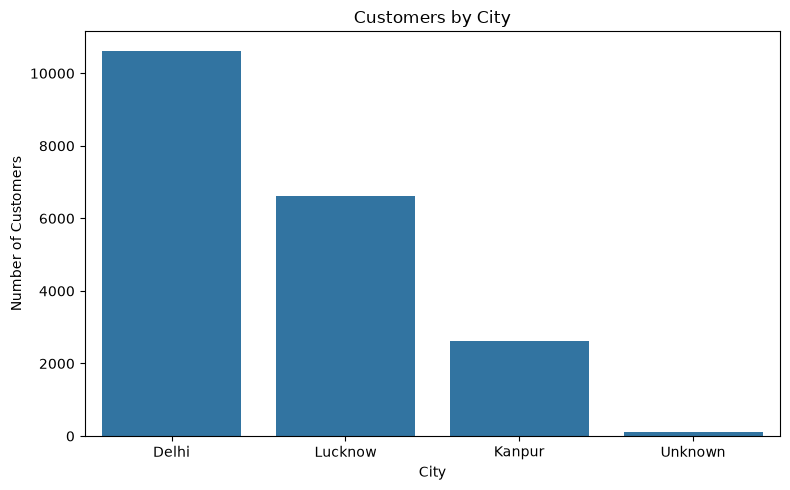

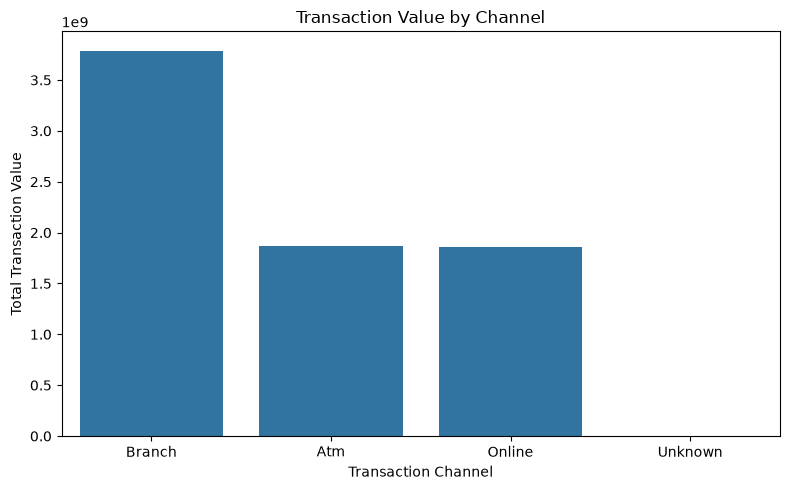

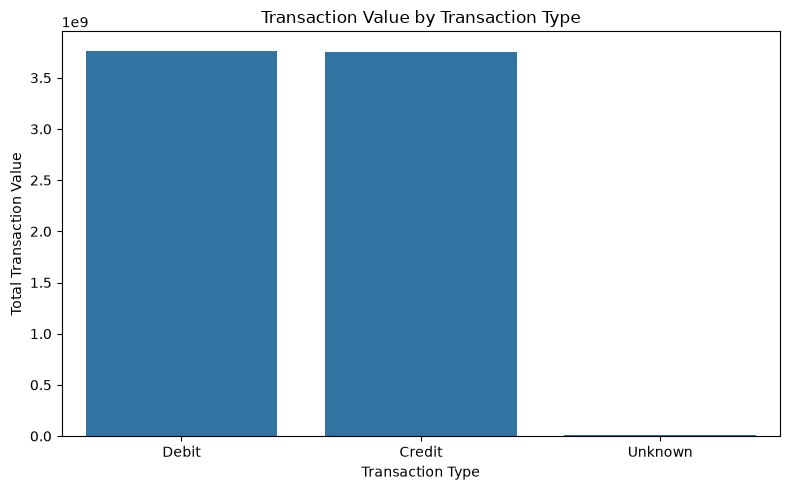

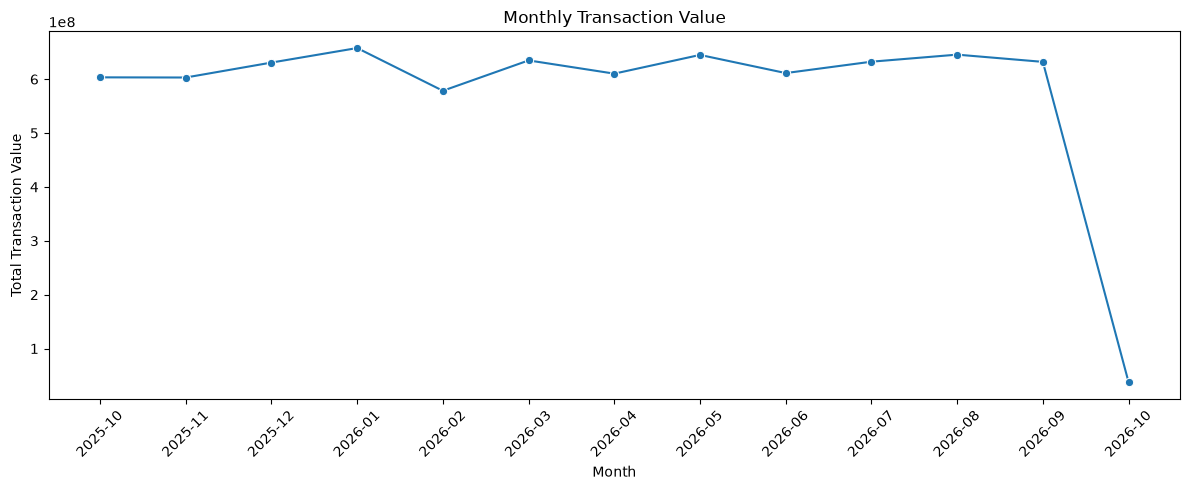

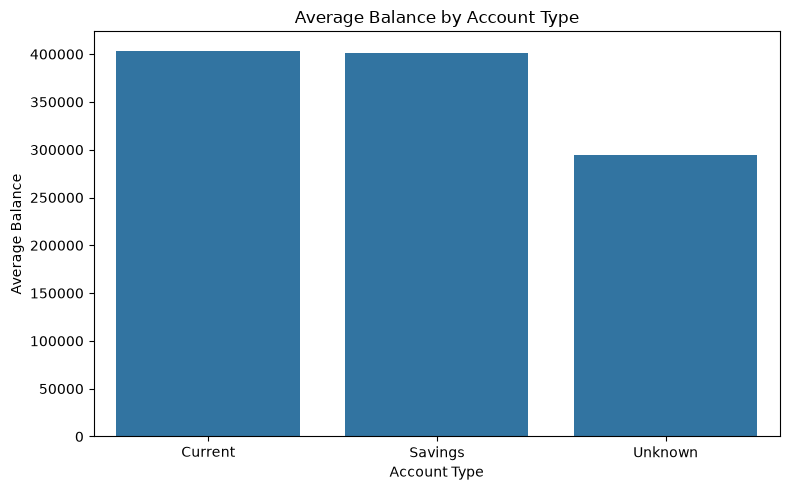

DAY 1 VISUALIZATIONS COMPLETE

Generated:
- customers_by_city.png
- transaction_value_by_channel.png
- transaction_value_by_type.png
- monthly_transaction_value.png
- average_balance_by_account_type.png


In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ============================================================
# DAY 1 — INITIAL BUSINESS VISUALIZATIONS
# ============================================================

# ------------------------------------------------------------
# 1. CUSTOMERS BY CITY
# ------------------------------------------------------------

query = """
SELECT
    City,
    COUNT(*) AS customer_count
FROM customers
GROUP BY City
ORDER BY customer_count DESC;
"""

city_df = pd.read_sql(query, engine)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=city_df,
    x="City",
    y="customer_count"
)
plt.title("Customers by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("../visualizations/customers_by_city.png")
plt.show()


# ------------------------------------------------------------
# 2. TRANSACTION VALUE BY CHANNEL
# ------------------------------------------------------------

query = """
SELECT
    Channel,
    COUNT(*) AS transaction_count,
    SUM(Amount) AS total_amount
FROM transactions
GROUP BY Channel
ORDER BY total_amount DESC;
"""

channel_df = pd.read_sql(query, engine)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=channel_df,
    x="Channel",
    y="total_amount"
)
plt.title("Transaction Value by Channel")
plt.xlabel("Transaction Channel")
plt.ylabel("Total Transaction Value")
plt.tight_layout()
plt.savefig("../visualizations/transaction_value_by_channel.png")
plt.show()


# ------------------------------------------------------------
# 3. TRANSACTION VALUE BY TYPE
# ------------------------------------------------------------

query = """
SELECT
    TransactionType,
    COUNT(*) AS transaction_count,
    SUM(Amount) AS total_amount
FROM transactions
GROUP BY TransactionType
ORDER BY total_amount DESC;
"""

type_df = pd.read_sql(query, engine)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=type_df,
    x="TransactionType",
    y="total_amount"
)
plt.title("Transaction Value by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Total Transaction Value")
plt.tight_layout()
plt.savefig("../visualizations/transaction_value_by_type.png")
plt.show()


# ------------------------------------------------------------
# 4. MONTHLY TRANSACTION ACTIVITY
# ------------------------------------------------------------

query = """
SELECT
    strftime('%Y-%m', TransactionDate) AS month,
    COUNT(*) AS transaction_count,
    SUM(Amount) AS total_amount
FROM transactions
GROUP BY month
ORDER BY month;
"""

monthly_df = pd.read_sql(query, engine)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_df,
    x="month",
    y="total_amount",
    marker="o"
)
plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Total Transaction Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../visualizations/monthly_transaction_value.png")
plt.show()


# ------------------------------------------------------------
# 5. ACCOUNT BALANCE BY ACCOUNT TYPE
# ------------------------------------------------------------

query = """
SELECT
    AccountType,
    AVG(Balance) AS average_balance,
    SUM(Balance) AS total_balance
FROM accounts
GROUP BY AccountType
ORDER BY total_balance DESC;
"""

balance_df = pd.read_sql(query, engine)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=balance_df,
    x="AccountType",
    y="average_balance"
)
plt.title("Average Balance by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Average Balance")
plt.tight_layout()
plt.savefig("../visualizations/average_balance_by_account_type.png")
plt.show()


print("DAY 1 VISUALIZATIONS COMPLETE")
print("\nGenerated:")
print("- customers_by_city.png")
print("- transaction_value_by_channel.png")
print("- transaction_value_by_type.png")
print("- monthly_transaction_value.png")
print("- average_balance_by_account_type.png")

INSIGHTS: DAY 1

In [57]:
print("=== DAY 1 BUSINESS SUMMARY ===")

print("\nCustomers by city:")
print(city_df)

print("\nTransaction value by channel:")
print(channel_df)

print("\nTransaction value by type:")
print(type_df)

print("\nMonthly transaction activity:")
print(monthly_df)

print("\nAccount balance:")
print(balance_df)

=== DAY 1 BUSINESS SUMMARY ===

Customers by city:
      City  customer_count
0    Delhi           10625
1  Lucknow            6627
2   Kanpur            2631
3  Unknown             117

Transaction value by channel:
   Channel  transaction_count  total_amount
0   Branch              49809  3.788772e+09
1      Atm              24923  1.871210e+09
2   Online              24928  1.859612e+09
3  Unknown                 40  2.926669e+06

Transaction value by type:
  TransactionType  transaction_count  total_amount
0           Debit              49814  3.765802e+09
1          Credit              49806  3.751007e+09
2         Unknown                 80  5.712293e+06

Monthly transaction activity:
      month  transaction_count  total_amount
0   2025-10               8025   603371384.0
1   2025-11               8090   603060987.0
2   2025-12               8332   630802274.0
3   2026-01               8669   657769702.0
4   2026-02               7669   578446371.0
5   2026-03               8492

# Day 1 — Initial Business Insights

### 1. Customer concentration
Delhi has 10,625 customers, representing approximately 53% of the customer base.
Lucknow has 6,627 customers (~33%), while Kanpur has 2,631 (~13%).
This indicates that the bank's customer base is heavily concentrated in Delhi and Lucknow.

### 2. Branch banking dominates transaction value
Branch transactions account for approximately ₹3.79B of transaction value, significantly higher than ATM (~₹1.87B) and Online (~₹1.86B).
This suggests that branch banking remains the dominant transaction channel in this dataset.

### 3. Debit and credit activity is highly balanced
Debit transactions account for approximately ₹3.77B while Credit transactions account for approximately ₹3.75B.
The transaction volumes are also almost identical (~49.8K each), indicating a relatively balanced flow of money in and out.

### 4. Transaction value is highly concentrated in large transactions
Large transactions account for approximately ₹7.49B of the total ₹7.52B transaction value.
Although small and medium transactions are much more numerous than their value contribution suggests, a relatively small number of large transactions dominate the monetary volume.

### 5. Current and savings accounts have similar balances
Current accounts have an average balance of approximately ₹403.7K, while Savings accounts average approximately ₹400.8K.
The two account types therefore have very similar balance profiles in this dataset.

# DAY 2 — CUSTOMER BEHAVIOR & EXPLORATORY DATA ANALYSIS

=== TRANSACTION STATISTICS ===
count    9.970000e+04
mean     7.545156e+04
std      6.563523e+04
min      1.000000e+00
25%      3.735600e+04
50%      7.503100e+04
75%      1.124262e+05
max      5.000000e+06
Name: Amount, dtype: float64

=== ACCOUNT BALANCE STATISTICS ===
count    3.000000e+04
mean     4.021694e+05
std      2.894789e+05
min     -5.000000e+03
25%      1.995475e+05
50%      3.994630e+05
75%      5.980238e+05
max      9.999999e+06
Name: Balance, dtype: float64


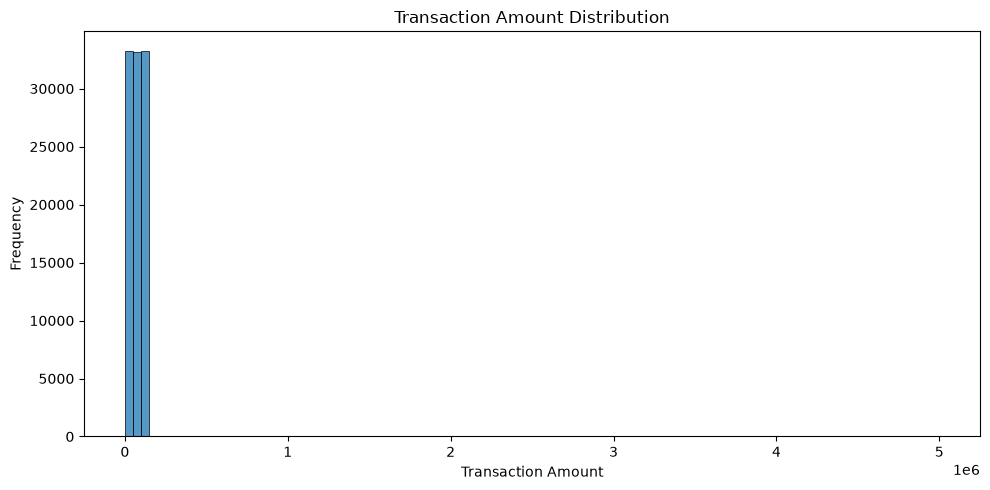

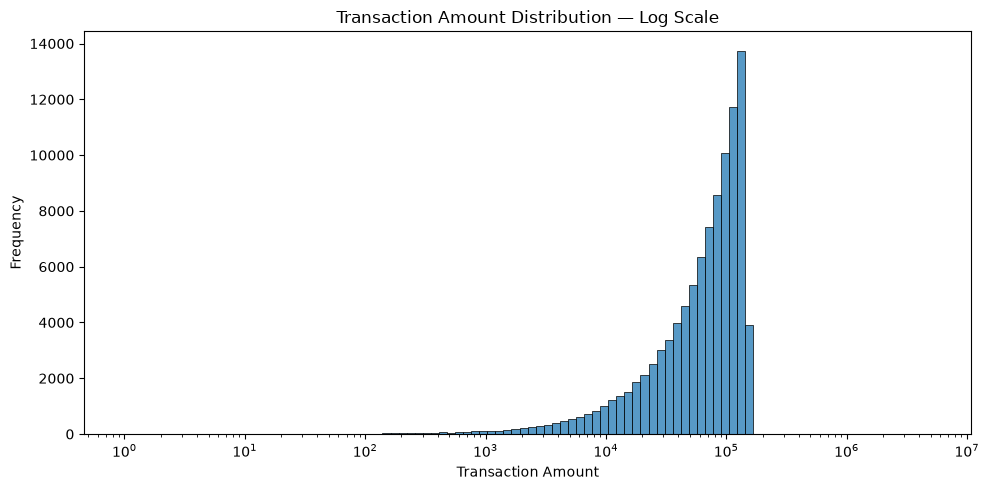

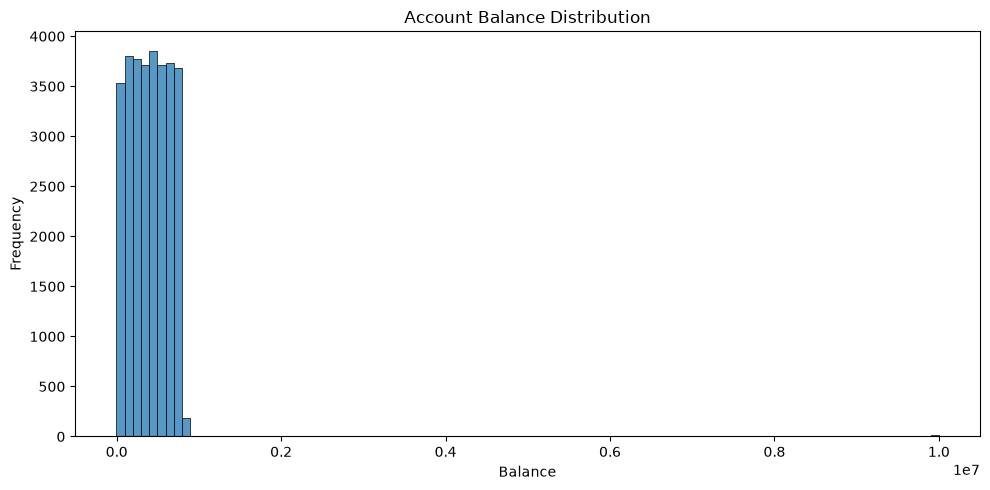


=== CUSTOMER FEATURE TABLE ===
   CustomerID  transaction_count  total_transaction_value  \
0           1                  3                 206238.0   
1           2                  6                 357578.0   
2           3                  7                 594335.0   
3           4                  7                 302708.0   
4           5                  7                 372873.0   

   average_transaction_value  max_transaction_value  total_balance  \
0               68746.000000               118177.0      1706970.0   
1               59596.333333               102514.0      1569192.0   
2               84905.000000               144399.0      2963124.0   
3               43244.000000               124642.0      3221512.0   
4               53267.571429               126759.0      1492380.0   

   account_count first_transaction_date last_transaction_date  total_credit  \
0              1             2026-04-14            2026-06-07           0.0   
1              2      

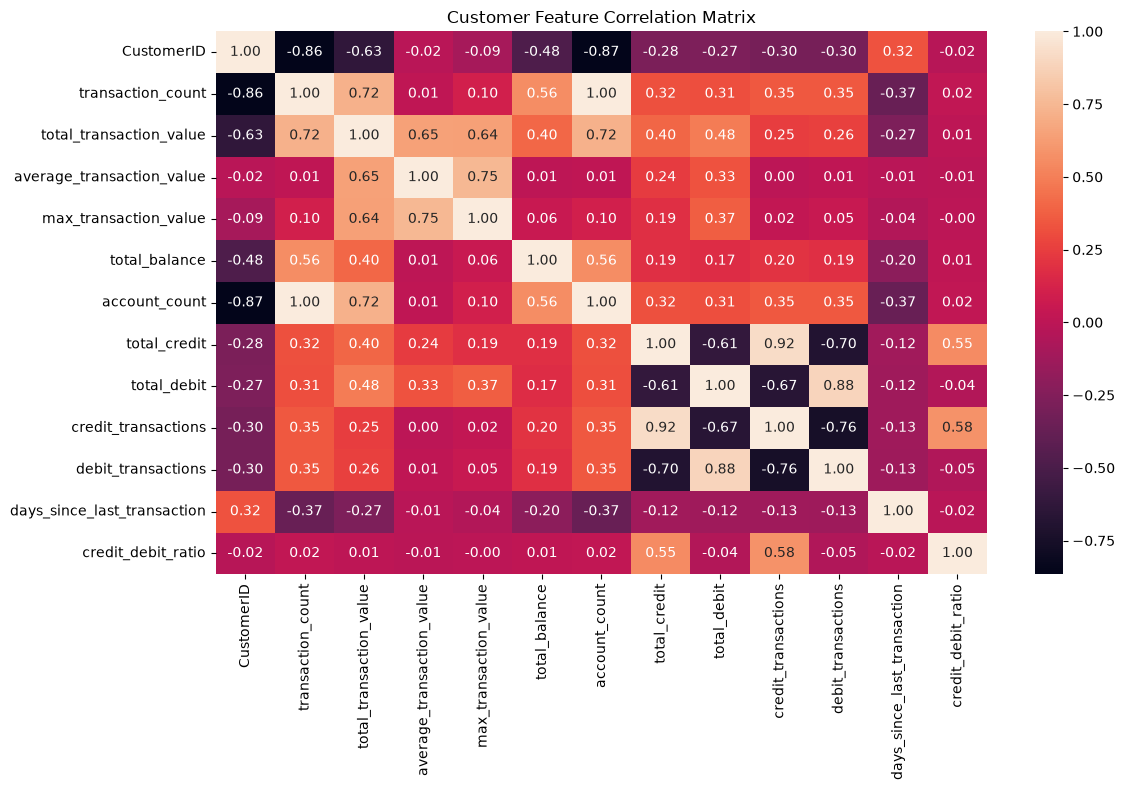


=== DAY 2 INITIAL CUSTOMER ANALYSIS COMPLETE ===


In [58]:
# ============================================================
# DAY 2 — CUSTOMER BEHAVIOR ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. BASIC STATISTICS
# ------------------------------------------------------------

print("=== TRANSACTION STATISTICS ===")
print(transactions_clean["Amount"].describe())

print("\n=== ACCOUNT BALANCE STATISTICS ===")
print(accounts_clean["Balance"].describe())


# ------------------------------------------------------------
# 2. TRANSACTION DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.histplot(
    transactions_clean["Amount"],
    bins=100
)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. TRANSACTION AMOUNT — LOG SCALE
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.histplot(
    transactions_clean["Amount"],
    bins=100,
    log_scale=True
)
plt.title("Transaction Amount Distribution — Log Scale")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. ACCOUNT BALANCE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.histplot(
    accounts_clean["Balance"],
    bins=100
)
plt.title("Account Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. CUSTOMER-LEVEL TRANSACTION FEATURES
# ------------------------------------------------------------

customer_transaction_features = (
    customers_clean[["CustomerID"]]
    .merge(
        accounts_clean[["AccountID", "CustomerID", "Balance"]],
        on="CustomerID",
        how="left"
    )
    .merge(
        transactions_clean[
            ["TransactionID", "AccountID", "TransactionDate",
             "TransactionType", "Amount", "Channel"]
        ],
        on="AccountID",
        how="left"
    )
)

# Aggregate transaction behavior per customer
customer_features = (
    customer_transaction_features
    .groupby("CustomerID")
    .agg(
        transaction_count=("TransactionID", "count"),
        total_transaction_value=("Amount", "sum"),
        average_transaction_value=("Amount", "mean"),
        max_transaction_value=("Amount", "max"),
        total_balance=("Balance", "sum"),
        account_count=("AccountID", "nunique"),
        first_transaction_date=("TransactionDate", "min"),
        last_transaction_date=("TransactionDate", "max")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 6. CREDIT / DEBIT FEATURES
# ------------------------------------------------------------

credit_debit = (
    transactions_clean
    .assign(
        credit_amount=lambda x:
            x["Amount"].where(x["TransactionType"] == "Credit", 0),

        debit_amount=lambda x:
            x["Amount"].where(x["TransactionType"] == "Debit", 0)
    )
    .merge(
        accounts_clean[["AccountID", "CustomerID"]],
        on="AccountID",
        how="left"
    )
    .groupby("CustomerID")
    .agg(
        total_credit=("credit_amount", "sum"),
        total_debit=("debit_amount", "sum"),
        credit_transactions=(
            "TransactionType",
            lambda x: (x == "Credit").sum()
        ),
        debit_transactions=(
            "TransactionType",
            lambda x: (x == "Debit").sum()
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# 7. MERGE CUSTOMER FEATURES
# ------------------------------------------------------------

customer_features = customer_features.merge(
    credit_debit,
    on="CustomerID",
    how="left"
)


# ------------------------------------------------------------
# 8. TRANSACTION RECENCY
# ------------------------------------------------------------

analysis_date = transactions_clean["TransactionDate"].max()

customer_features["days_since_last_transaction"] = (
    analysis_date -
    customer_features["last_transaction_date"]
).dt.days


# ------------------------------------------------------------
# 9. CREDIT / DEBIT RATIO
# ------------------------------------------------------------

customer_features["credit_debit_ratio"] = (
    customer_features["total_credit"] /
    customer_features["total_debit"].replace(0, np.nan)
)


# ------------------------------------------------------------
# 10. VIEW CUSTOMER FEATURE TABLE
# ------------------------------------------------------------

print("\n=== CUSTOMER FEATURE TABLE ===")

print(customer_features.head())

print("\nShape:")
print(customer_features.shape)

print("\nStatistics:")
print(customer_features.describe())


# ------------------------------------------------------------
# 11. TOP CUSTOMERS BY TRANSACTION VALUE
# ------------------------------------------------------------

print("\n=== TOP 10 CUSTOMERS BY TRANSACTION VALUE ===")

print(
    customer_features
    .sort_values(
        "total_transaction_value",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 12. TOP CUSTOMERS BY TRANSACTION COUNT
# ------------------------------------------------------------

print("\n=== TOP 10 MOST ACTIVE CUSTOMERS ===")

print(
    customer_features
    .sort_values(
        "transaction_count",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 13. CORRELATION MATRIX
# ------------------------------------------------------------

numeric_features = customer_features.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_features.corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Customer Feature Correlation Matrix")
plt.tight_layout()
plt.show()


print("\n=== DAY 2 INITIAL CUSTOMER ANALYSIS COMPLETE ===")

In [59]:
customer_features.head()

,CustomerID,transaction_count,total_transaction_value,average_transaction_value,max_transaction_value,total_balance,account_count,first_transaction_date,last_transaction_date,total_credit,total_debit,credit_transactions,debit_transactions,days_since_last_transaction,credit_debit_ratio
0,1,3,206238.0,68746.000000,118177.0,1706970.0,1,2026-04-14,2026-06-07,0.0,206238.0,0,3,117,0.0
1,2,6,357578.0,59596.333333,102514.0,1569192.0,2,2025-10-12,2026-07-26,357578.0,0.0,6,0,68,NaN
2,3,7,594335.0,84905.000000,144399.0,2963124.0,2,2025-11-12,2026-09-24,0.0,594335.0,0,7,8,0.0
3,4,7,302708.0,43244.000000,124642.0,3221512.0,2,2025-10-27,2026-09-10,302708.0,0.0,7,0,22,NaN
4,5,7,372873.0,53267.571429,126759.0,1492380.0,2,2025-11-25,2026-09-04,0.0,372873.0,0,7,28,0.0


=== MISSING VALUES ===
CustomerID                        0
transaction_count                 0
total_transaction_value           0
average_transaction_value         0
max_transaction_value             0
total_balance                     0
account_count                     0
first_transaction_date            0
last_transaction_date             0
total_credit                      0
total_debit                       0
credit_transactions               0
debit_transactions                0
days_since_last_transaction       0
credit_debit_ratio             9976
dtype: int64


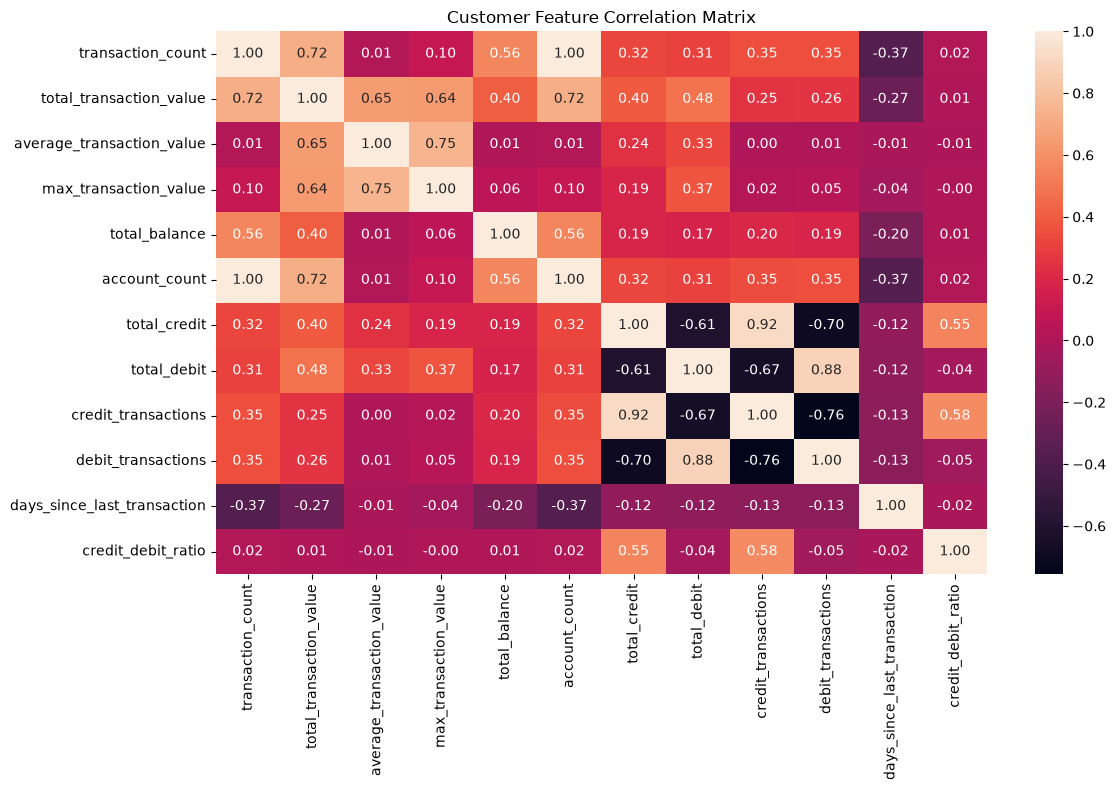


=== FINAL CUSTOMER FEATURE TABLE ===
(20000, 15)

Columns:
['CustomerID', 'transaction_count', 'total_transaction_value', 'average_transaction_value', 'max_transaction_value', 'total_balance', 'account_count', 'first_transaction_date', 'last_transaction_date', 'total_credit', 'total_debit', 'credit_transactions', 'debit_transactions', 'days_since_last_transaction', 'credit_debit_ratio']

First 5 customers:


,CustomerID,transaction_count,total_transaction_value,average_transaction_value,max_transaction_value,total_balance,account_count,first_transaction_date,last_transaction_date,total_credit,total_debit,credit_transactions,debit_transactions,days_since_last_transaction,credit_debit_ratio
0,1,3,206238.0,68746.000000,118177.0,1706970.0,1,2026-04-14,2026-06-07,0.0,206238.0,0,3,117,0.0
1,2,6,357578.0,59596.333333,102514.0,1569192.0,2,2025-10-12,2026-07-26,357578.0,0.0,6,0,68,NaN
2,3,7,594335.0,84905.000000,144399.0,2963124.0,2,2025-11-12,2026-09-24,0.0,594335.0,0,7,8,0.0
3,4,7,302708.0,43244.000000,124642.0,3221512.0,2,2025-10-27,2026-09-10,302708.0,0.0,7,0,22,NaN
4,5,7,372873.0,53267.571429,126759.0,1492380.0,2,2025-11-25,2026-09-04,0.0,372873.0,0,7,28,0.0


In [60]:
# ============================================================
# DAY 2 — FINALIZE CUSTOMER FEATURES
# ============================================================

# Never use CustomerID as a numerical analytical feature.
# Keep it only as an identifier.
customer_features = customer_features.copy()


# ------------------------------------------------------------
# 1. HANDLE MISSING NUMERIC FEATURES
# ------------------------------------------------------------

numeric_cols = [
    "transaction_count",
    "total_transaction_value",
    "average_transaction_value",
    "max_transaction_value",
    "total_balance",
    "account_count",
    "total_credit",
    "total_debit",
    "credit_transactions",
    "debit_transactions",
    "days_since_last_transaction",
    "credit_debit_ratio"
]

# Features representing "no activity" should be 0.
zero_fill_cols = [
    "transaction_count",
    "total_transaction_value",
    "average_transaction_value",
    "max_transaction_value",
    "total_balance",
    "account_count",
    "total_credit",
    "total_debit",
    "credit_transactions",
    "debit_transactions"
]

customer_features[zero_fill_cols] = (
    customer_features[zero_fill_cols]
    .fillna(0)
)


# ------------------------------------------------------------
# 2. CREDIT/DEBIT RATIO
# ------------------------------------------------------------

customer_features["credit_debit_ratio"] = (
    customer_features["total_credit"] /
    customer_features["total_debit"].replace(0, np.nan)
)

# Customers with no debit activity don't have a meaningful ratio.
# We leave these as NaN rather than pretending the ratio is 0.


# ------------------------------------------------------------
# 3. CHECK MISSING VALUES
# ------------------------------------------------------------

print("=== MISSING VALUES ===")
print(
    customer_features.isna().sum()
)


# ------------------------------------------------------------
# 4. REMOVE ID FROM NUMERICAL CORRELATION
# ------------------------------------------------------------

analysis_features = customer_features.drop(
    columns=["CustomerID"]
)

numeric_analysis = analysis_features.select_dtypes(
    include=np.number
)


# ------------------------------------------------------------
# 5. CLEAN CORRELATION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_analysis.corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Customer Feature Correlation Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. FINAL FEATURE TABLE
# ------------------------------------------------------------

print("\n=== FINAL CUSTOMER FEATURE TABLE ===")
print(customer_features.shape)

print("\nColumns:")
print(customer_features.columns.tolist())

print("\nFirst 5 customers:")
display(customer_features.head())

In [61]:
# ============================================================
# DAY 2 — OUTLIER ANALYSIS
# ============================================================

def outlier_summary(df, column):
    """
    Calculate IQR-based outlier information.
    """
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    # here we are returning a map(with key value pair)
    return {
        "column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percentage": len(outliers) / len(df) * 100
    }


# ------------------------------------------------------------
# TRANSACTION OUTLIERS
# ------------------------------------------------------------

transaction_outlier = outlier_summary(
    transactions_clean,
    "Amount"
)

print("=== TRANSACTION OUTLIERS ===")

for key, value in transaction_outlier.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# ACCOUNT BALANCE OUTLIERS
# ------------------------------------------------------------

balance_outlier = outlier_summary(
    accounts_clean,
    "Balance"
)

print("\n=== ACCOUNT BALANCE OUTLIERS ===")

for key, value in balance_outlier.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# TOP TRANSACTIONS
# ------------------------------------------------------------

print("\n=== TOP 10 TRANSACTIONS ===")

display(
    transactions_clean[
        [
            "TransactionID",
            "AccountID",
            "TransactionType",
            "Amount",
            "Channel"
        ]
    ]
    .sort_values(
        "Amount",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# TOP ACCOUNT BALANCES
# ------------------------------------------------------------

print("\n=== TOP 10 ACCOUNT BALANCES ===")

display(
    accounts_clean[
        [
            "AccountID",
            "CustomerID",
            "AccountType",
            "Balance"
        ]
    ]
    .sort_values(
        "Balance",
        ascending=False
    )
    .head(10)
)

=== TRANSACTION OUTLIERS ===
column: Amount
Q1: 37356.0
Q3: 112426.25
IQR: 75070.25
lower_bound: -75249.375
upper_bound: 225031.625
outlier_count: 10
outlier_percentage: 0.010030090270812437

=== ACCOUNT BALANCE OUTLIERS ===
column: Balance
Q1: 199547.5
Q3: 598023.75
IQR: 398476.25
lower_bound: -398166.875
upper_bound: 1195738.125
outlier_count: 10
outlier_percentage: 0.03333333333333333

=== TOP 10 TRANSACTIONS ===


,TransactionID,AccountID,TransactionType,Amount,Channel
30688,30689,1690.0,Debit,5000000.0,Branch
93606,93607,4608.0,Debit,5000000.0,Branch
91291,91292,2293.0,Credit,5000000.0,Atm
55340,55341,26342.0,Debit,5000000.0,Online
35412,35413,6414.0,Debit,5000000.0,Branch
91876,91877,2878.0,Debit,5000000.0,Branch
70450,70451,11452.0,Debit,5000000.0,Branch
31376,31377,2378.0,Debit,5000000.0,Online
11293,11294,12295.0,Credit,5000000.0,Branch
87265,87266,28267.0,Credit,5000000.0,Branch



=== TOP 10 ACCOUNT BALANCES ===


,AccountID,CustomerID,AccountType,Balance
5158,6159,5160,Current,9999999.0
28596,29597,8598,Current,9999999.0
6692,7693,6694,Current,9999999.0
24583,25584,4585,Savings,9999999.0
21398,22399,1400,Current,9999999.0
14458,15459,14460,Current,9999999.0
4568,5569,4570,Current,9999999.0
7918,8919,7920,Current,9999999.0
18476,19477,18478,Current,9999999.0
16748,17749,16750,Current,9999999.0



=== ACTIVITY SEGMENTS ===
activity_segment
Low Activity            91
Medium Activity       9910
High Activity         9999
Very High Activity       0
Name: count, dtype: int64
=== VALUE SEGMENTS ===
value_segment
Low Value          5000
Medium Value       5000
High Value         5000
Very High Value    5000
Name: count, dtype: int64

=== ACTIVITY SEGMENTS ===
activity_segment
Low Activity            91
Medium Activity       9910
High Activity         9999
Very High Activity       0
Name: count, dtype: int64

=== RECENCY SEGMENTS ===
recency_segment
Recent         7366
Very Recent    7054
Inactive       4228
Dormant        1352
Name: count, dtype: int64

=== VERY HIGH VALUE CUSTOMERS ===


,CustomerID,transaction_count,total_transaction_value,average_transaction_value,total_balance,account_count,days_since_last_transaction
3608,3609,7,5632098.0,8.045854e+05,3775690.0,2,32
1378,1379,7,5584539.0,7.977913e+05,4505842.0,2,5
1293,1294,7,5506107.0,7.865867e+05,2202577.0,2,24
5414,5415,7,5498247.0,7.854639e+05,1955999.0,2,50
1878,1879,7,5496064.0,7.851520e+05,4450802.0,2,9
7267,7268,7,5443188.0,7.775983e+05,3059892.0,2,53
690,691,7,5268688.0,7.526697e+05,3811706.0,2,13
5342,5343,7,5201987.0,7.431410e+05,1251121.0,2,10
11295,11296,3,5178031.0,1.726010e+06,1043049.0,1,124
10452,10453,3,5107404.0,1.702468e+06,127581.0,1,5



=== DORMANT CUSTOMERS ===


,CustomerID,transaction_count,total_transaction_value,total_balance,days_since_last_transaction
1075,1076,7,734899.0,2460616.0,202
480,481,7,708180.0,357315.0,221
2657,2658,7,706822.0,3079278.0,197
7526,7527,7,697102.0,4143706.0,198
2447,2448,7,696714.0,2877030.0,187
7176,7177,7,680928.0,2486901.0,213
5559,5560,7,663545.0,1313654.0,201
2547,2548,7,661909.0,4029846.0,208
5671,5672,7,661889.0,3623694.0,193
5785,5786,7,660943.0,2429999.0,182


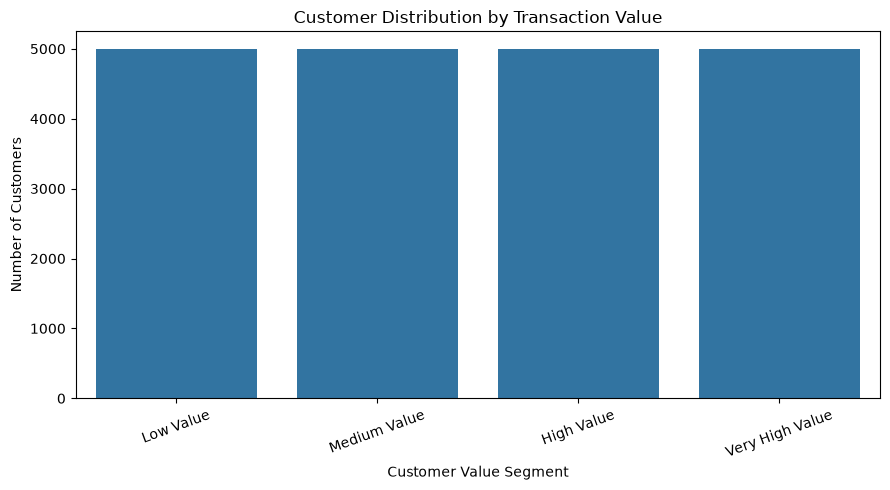

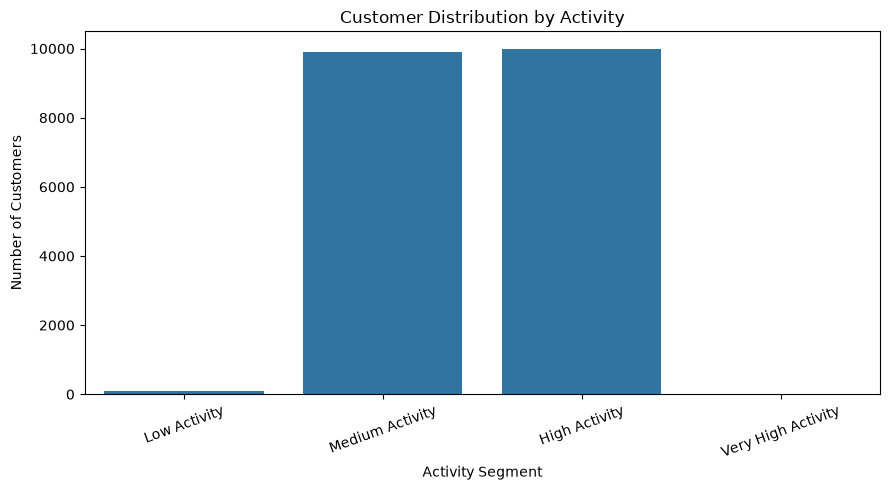

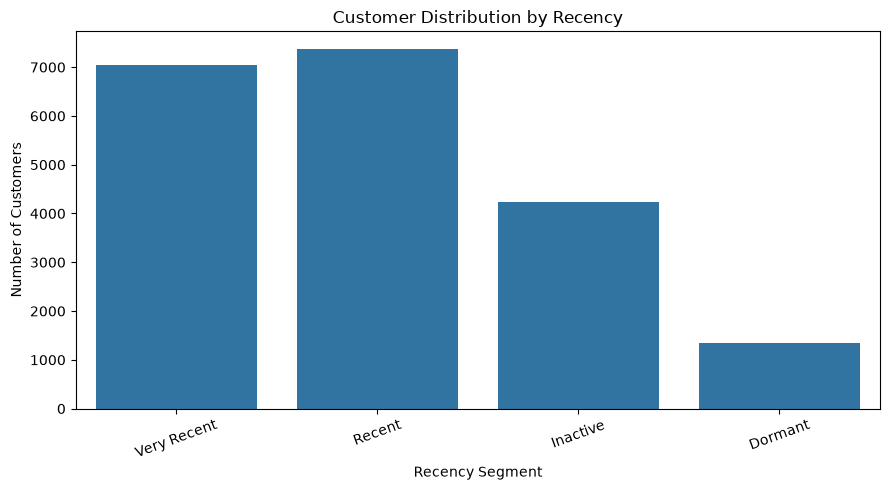


=== DAY 2 CUSTOMER ANALYSIS COMPLETE ===
Customer feature dataset: (20000, 18)


In [62]:
# ============================================================
# DAY 2 — CUSTOMER BEHAVIOR SEGMENTATION
# ============================================================

# ------------------------------------------------------------
# 1. CUSTOMER VALUE QUARTILES
# ------------------------------------------------------------

# sorts the data and divides then into categories (based on quantiles)
customer_features["value_segment"] = pd.qcut(
    customer_features["total_transaction_value"],
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ],
    duplicates="drop"
)


# ------------------------------------------------------------
# 2. ACTIVITY SEGMENTS
# ------------------------------------------------------------

# here we specify the bin widths
customer_features["activity_segment"] = pd.cut(
    customer_features["transaction_count"],
    bins=[
        -1,
        2,
        5,
        10,
        float("inf")
    ],
    labels=[
        "Low Activity",
        "Medium Activity",
        "High Activity",
        "Very High Activity"
    ]
)

print("\n=== ACTIVITY SEGMENTS ===")

print(
    customer_features["activity_segment"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 3. RECENCY SEGMENTS
# ------------------------------------------------------------

customer_features["recency_segment"] = pd.cut(
    customer_features["days_since_last_transaction"],
    bins=[
        -1,
        30,
        90,
        180,
        float("inf")
    ],
    labels=[
        "Very Recent",
        "Recent",
        "Inactive",
        "Dormant"
    ]
)


# ------------------------------------------------------------
# 4. CUSTOMER BEHAVIOR SUMMARY
# ------------------------------------------------------------

print("=== VALUE SEGMENTS ===")

print(
    customer_features["value_segment"]
    .value_counts()
    .sort_index()
)


print("\n=== ACTIVITY SEGMENTS ===")

print(
    customer_features["activity_segment"]
    .value_counts()
    .sort_index()
)


print("\n=== RECENCY SEGMENTS ===")

print(
    customer_features["recency_segment"]
    .value_counts()
)


# ------------------------------------------------------------
# 5. HIGH-VALUE CUSTOMERS
# ------------------------------------------------------------

high_value = customer_features[
    customer_features["value_segment"] == "Very High Value"
]

print("\n=== VERY HIGH VALUE CUSTOMERS ===")

display(
    high_value[
        [
            "CustomerID",
            "transaction_count",
            "total_transaction_value",
            "average_transaction_value",
            "total_balance",
            "account_count",
            "days_since_last_transaction"
        ]
    ]
    .sort_values(
        "total_transaction_value",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 6. DORMANT CUSTOMERS
# ------------------------------------------------------------

dormant = customer_features[
    customer_features["recency_segment"] == "Dormant"
]

print("\n=== DORMANT CUSTOMERS ===")

display(
    dormant[
        [
            "CustomerID",
            "transaction_count",
            "total_transaction_value",
            "total_balance",
            "days_since_last_transaction"
        ]
    ]
    .sort_values(
        "total_transaction_value",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 7. CUSTOMER VALUE VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.countplot(
    data=customer_features,
    x="value_segment",
    order=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ]
)

plt.title("Customer Distribution by Transaction Value")
plt.xlabel("Customer Value Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../visualizations/customer_value_segments.png")
plt.show()


# ------------------------------------------------------------
# 8. CUSTOMER ACTIVITY VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.countplot(
    data=customer_features,
    x="activity_segment",
    order=[
        "Low Activity",
        "Medium Activity",
        "High Activity",
        "Very High Activity"
    ]
)

plt.title("Customer Distribution by Activity")
plt.xlabel("Activity Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../visualizations/customer_activity_segments.png")
plt.show()


# ------------------------------------------------------------
# 9. RECENCY VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.countplot(
    data=customer_features,
    x="recency_segment",
    order=[
        "Very Recent",
        "Recent",
        "Inactive",
        "Dormant"
    ]
)

plt.title("Customer Distribution by Recency")
plt.xlabel("Recency Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../visualizations/customer_recency_segments.png")
plt.show()


# ------------------------------------------------------------
# 10. SAVE CUSTOMER FEATURE DATASET
# ------------------------------------------------------------

customer_features.to_csv(
    "../data/cleaned/customer_features.csv",
    index=False
)


print("\n=== DAY 2 CUSTOMER ANALYSIS COMPLETE ===")
print(
    f"Customer feature dataset: {customer_features.shape}"
)

In [63]:
# ============================================================
# DAY 2 — FINAL VALIDATION
# ============================================================

print("=== CUSTOMER FEATURE DATASET ===")

print("Shape:", customer_features.shape)

print("\nMissing values:")
print(customer_features.isna().sum())

print("\nDuplicate customers:")
print(customer_features["CustomerID"].duplicated().sum())

print("\nValue segments:")
print(customer_features["value_segment"].value_counts())

print("\nActivity segments:")
print(customer_features["activity_segment"].value_counts())

print("\nRecency segments:")
print(customer_features["recency_segment"].value_counts())

print("\nSaved file:")
print("../data/cleaned/customer_features.csv")

=== CUSTOMER FEATURE DATASET ===
Shape: (20000, 18)

Missing values:
CustomerID                        0
transaction_count                 0
total_transaction_value           0
average_transaction_value         0
max_transaction_value             0
total_balance                     0
account_count                     0
first_transaction_date            0
last_transaction_date             0
total_credit                      0
total_debit                       0
credit_transactions               0
debit_transactions                0
days_since_last_transaction       0
credit_debit_ratio             9976
value_segment                     0
activity_segment                  0
recency_segment                   0
dtype: int64

Duplicate customers:
0

Value segments:
value_segment
Low Value          5000
Medium Value       5000
High Value         5000
Very High Value    5000
Name: count, dtype: int64

Activity segments:
activity_segment
High Activity         9999
Medium Activity       9910
Lo

DAY 3:---

In [64]:
# ============================================
# DAY 3 - BLOCK 1
# DATE VALIDATION + TIME FEATURES
# ============================================

import numpy as np
import pandas as pd

customer_features = customer_features.copy()


# --------------------------------------------
# 1. Make sure ALL relevant dates are datetime
# --------------------------------------------

customers_clean["DOB"] = pd.to_datetime(
    customers_clean["DOB"],
    errors="coerce"
)

customers_clean["JoinDate"] = pd.to_datetime(
    customers_clean["JoinDate"],
    errors="coerce"
)

transactions_clean["TransactionDate"] = pd.to_datetime(
    transactions_clean["TransactionDate"],
    errors="coerce"
)

customer_features["first_transaction_date"] = pd.to_datetime(
    customer_features["first_transaction_date"],
    errors="coerce"
)

customer_features["last_transaction_date"] = pd.to_datetime(
    customer_features["last_transaction_date"],
    errors="coerce"
)


# --------------------------------------------
# 2. Inspect date ranges
# --------------------------------------------

print("=== DATE RANGES ===")

print("\nCustomer DOB:")
print(customers_clean["DOB"].min(), "to",
      customers_clean["DOB"].max())

print("\nCustomer Join Date:")
print(customers_clean["JoinDate"].min(), "to",
      customers_clean["JoinDate"].max())

print("\nTransaction Date:")
print(transactions_clean["TransactionDate"].min(), "to",
      transactions_clean["TransactionDate"].max())


# --------------------------------------------
# 3. Add JoinDate to customer_features
# --------------------------------------------

join_dates = customers_clean[
    ["CustomerID", "JoinDate"]
].copy()

# Remove JoinDate first if it already exists
# (prevents duplicate JoinDate_x / JoinDate_y)
if "JoinDate" in customer_features.columns:
    customer_features = customer_features.drop(
        columns=["JoinDate"]
    )

customer_features = customer_features.merge(
    join_dates,
    on="CustomerID",
    how="left"
)


# --------------------------------------------
# 4. Define analysis date
# --------------------------------------------

analysis_date = transactions_clean[
    "TransactionDate"
].max()

print("\nAnalysis date:", analysis_date)


# --------------------------------------------
# 5. Customer tenure
# --------------------------------------------

customer_features["tenure_days"] = (
    analysis_date -
    customer_features["JoinDate"]
).dt.days


# --------------------------------------------
# 6. Remove impossible tenure
# --------------------------------------------

customer_features.loc[
    customer_features["tenure_days"] < 0,
    "tenure_days"
] = np.nan


# --------------------------------------------
# 7. Convert tenure to years
# --------------------------------------------

customer_features["tenure_years"] = (
    customer_features["tenure_days"] / 365.25
)


# --------------------------------------------
# 8. Transaction activity span
# --------------------------------------------

customer_features["activity_span_days"] = (
    customer_features["last_transaction_date"]
    -
    customer_features["first_transaction_date"]
).dt.days

customer_features.loc[
    customer_features["activity_span_days"] < 0,
    "activity_span_days"
] = np.nan


# --------------------------------------------
# 9. Transaction frequency
# --------------------------------------------

customer_features["transactions_per_month"] = (
    customer_features["transaction_count"]
    /
    (customer_features["activity_span_days"] / 30 + 1)
)


# --------------------------------------------
# 10. Daily transaction value
# --------------------------------------------

customer_features["daily_transaction_value"] = (
    customer_features["total_transaction_value"]
    /
    (customer_features["activity_span_days"] + 1)
)


# --------------------------------------------
# 11. Check results
# --------------------------------------------

new_features = [
    "CustomerID",
    "JoinDate",
    "tenure_days",
    "tenure_years",
    "activity_span_days",
    "transactions_per_month",
    "daily_transaction_value"
]

print("\n=== NEW FEATURES ===")
print(customer_features[new_features].head())

print("\n=== MISSING VALUES ===")
print(
    customer_features[
        [
            "tenure_days",
            "tenure_years",
            "activity_span_days",
            "transactions_per_month",
            "daily_transaction_value"
        ]
    ].isna().sum()
)

=== DATE RANGES ===

Customer DOB:
0931-08-04 00:00:00 to 2035-01-01 00:00:00

Customer Join Date:
1971-12-30 00:00:00 to 2026-10-01 00:00:00

Transaction Date:
2025-10-03 00:00:00 to 2026-10-02 00:00:00

Analysis date: 2026-10-02 00:00:00

=== NEW FEATURES ===
   CustomerID   JoinDate  tenure_days  tenure_years  activity_span_days  \
0           1 2026-10-01          1.0      0.002738                54.0   
1           2 2026-09-30          2.0      0.005476               287.0   
2           3 2026-09-29          3.0      0.008214               316.0   
3           4 2026-09-28          4.0      0.010951               318.0   
4           5 2026-09-27          5.0      0.013689               283.0   

   transactions_per_month  daily_transaction_value  
0                1.071429              3749.781818  
1                0.567823              1241.590278  
2                0.606936              1874.873817  
3                0.603448               948.927900  
4                0.670

In [65]:
# ============================================
# DAY 3 - BLOCK 2
# CUSTOMER BEHAVIOR FEATURES
# ============================================

# --------------------------------------------
# 1. Credit / Debit percentages
# --------------------------------------------

customer_features["credit_ratio"] = (
    customer_features["total_credit"] /
    customer_features["total_transaction_value"]
)

customer_features["debit_ratio"] = (
    customer_features["total_debit"] /
    customer_features["total_transaction_value"]
)


# --------------------------------------------
# 2. Average credit/debit transaction size
# --------------------------------------------

customer_features["avg_credit_value"] = (
    customer_features["total_credit"] /
    customer_features["credit_transactions"].replace(0, np.nan)
)

customer_features["avg_debit_value"] = (
    customer_features["total_debit"] /
    customer_features["debit_transactions"].replace(0, np.nan)
)


# --------------------------------------------
# 3. Balance-related features
# --------------------------------------------

customer_features["balance_per_account"] = (
    customer_features["total_balance"] /
    customer_features["account_count"].replace(0, np.nan)
)

customer_features["transactions_per_account"] = (
    customer_features["transaction_count"] /
    customer_features["account_count"].replace(0, np.nan)
)

customer_features["transaction_value_per_account"] = (
    customer_features["total_transaction_value"] /
    customer_features["account_count"].replace(0, np.nan)
)


# --------------------------------------------
# 4. Average transaction compared with balance
# --------------------------------------------

customer_features["transaction_to_balance_ratio"] = (
    customer_features["average_transaction_value"] /
    customer_features["balance_per_account"].replace(0, np.nan)
)


# --------------------------------------------
# 5. High-value transaction behavior
# --------------------------------------------

customer_features["large_transaction_flag"] = (
    customer_features["max_transaction_value"] >= 500000
).astype(int)


# --------------------------------------------
# 6. High activity behavior
# --------------------------------------------

customer_features["high_activity_flag"] = (
    customer_features["transaction_count"] >= 10
).astype(int)


# --------------------------------------------
# 7. High customer value
# --------------------------------------------

value_threshold = customer_features[
    "total_transaction_value"
].quantile(0.75)

customer_features["high_value_flag"] = (
    customer_features["total_transaction_value"]
    >= value_threshold
).astype(int)


# --------------------------------------------
# 8. Recent activity
# --------------------------------------------

customer_features["recent_activity_flag"] = (
    customer_features["days_since_last_transaction"] <= 30
).astype(int)


# --------------------------------------------
# 9. Inactive customer
# --------------------------------------------

customer_features["inactive_flag"] = (
    customer_features["days_since_last_transaction"] > 180
).astype(int)


# --------------------------------------------
# 10. Display important features
# --------------------------------------------

behavior_features = [
    "CustomerID",
    "credit_ratio",
    "debit_ratio",
    "avg_credit_value",
    "avg_debit_value",
    "balance_per_account",
    "transactions_per_account",
    "transaction_value_per_account",
    "transaction_to_balance_ratio",
    "large_transaction_flag",
    "high_activity_flag",
    "high_value_flag",
    "recent_activity_flag",
    "inactive_flag"
]

print(customer_features[behavior_features].head())

print("\n=== FEATURE SUMMARY ===")
print(customer_features[
    behavior_features[1:]
].describe().T)

   CustomerID  credit_ratio  debit_ratio  avg_credit_value  avg_debit_value  \
0           1           0.0          1.0               NaN     68746.000000   
1           2           1.0          0.0      59596.333333              NaN   
2           3           0.0          1.0               NaN     84905.000000   
3           4           1.0          0.0      43244.000000              NaN   
4           5           0.0          1.0               NaN     53267.571429   

   balance_per_account  transactions_per_account  \
0            1706970.0                       3.0   
1             784596.0                       3.0   
2            1481562.0                       3.5   
3            1610756.0                       3.5   
4             746190.0                       3.5   

   transaction_value_per_account  transaction_to_balance_ratio  \
0                       206238.0                      0.040274   
1                       178789.0                      0.075958   
2             

In [66]:
# ============================================
# DAY 3 - BLOCK 3
# LOG TRANSFORMATIONS
# ============================================

log_columns = [
    "total_transaction_value",
    "average_transaction_value",
    "max_transaction_value",
    "total_balance",
    "balance_per_account",
    "daily_transaction_value"
]

for col in log_columns:
    customer_features[f"log_{col}"] = np.log1p(
        customer_features[col].clip(lower=0)
    )


# --------------------------------------------
# Compare original vs transformed
# --------------------------------------------

comparison = customer_features[
    [
        "total_transaction_value",
        "log_total_transaction_value",
        "total_balance",
        "log_total_balance"
    ]
]

print(comparison.head(10))

print("\nOriginal statistics:")
print(customer_features[
    ["total_transaction_value", "total_balance"]
].describe())

print("\nLog-transformed statistics:")
print(customer_features[
    ["log_total_transaction_value", "log_total_balance"]
].describe())

   total_transaction_value  log_total_transaction_value  total_balance  \
0                 206238.0                    12.236791      1706970.0   
1                 357578.0                    12.787112      1569192.0   
2                 594335.0                    13.295200      2963124.0   
3                 302708.0                    12.620527      3221512.0   
4                 372873.0                    12.828996      1492380.0   
5                 431792.0                    12.975702      3069971.0   
6                 667547.0                    13.411367      3476629.0   
7                 318352.0                    12.670916      1195373.0   
8                 626180.0                    13.347395      2608703.0   
9                 614275.0                    13.328200      1520655.0   

   log_total_balance  
0          14.350231  
1          14.266072  
2          14.901755  
3          14.985362  
4          14.215883  
5          14.937179  
6          15.061574  
7

In [67]:
# ============================================
# DAY 3 - BLOCK 4
# FINAL FEATURE CLEANING
# ============================================

# --------------------------------------------
# 1. Replace infinities
# --------------------------------------------

customer_features = customer_features.replace(
    [np.inf, -np.inf],
    np.nan
)


# --------------------------------------------
# 2. Fill numerical missing values
# --------------------------------------------

numeric_columns = customer_features.select_dtypes(
    include=np.number
).columns

customer_features[numeric_columns] = (
    customer_features[numeric_columns]
    .fillna(customer_features[numeric_columns].median())
)


# --------------------------------------------
# 3. Check categorical features
# --------------------------------------------

categorical_columns = customer_features.select_dtypes(
    include=["object", "category"]
).columns

print("Categorical columns:")
print(list(categorical_columns))


# --------------------------------------------
# 4. Check numerical features
# --------------------------------------------

print("\nNumber of numerical features:")
print(len(numeric_columns))


# --------------------------------------------
# 5. Final validation
# --------------------------------------------

print("\n=== FINAL VALIDATION ===")

print("Shape:", customer_features.shape)

print("\nMissing values:")
print(customer_features.isna().sum().sum())

print("\nDuplicate CustomerIDs:")
print(customer_features["CustomerID"].duplicated().sum())


# --------------------------------------------
# 6. Save Day 3 dataset
# --------------------------------------------

customer_features.to_csv(
    "../data/cleaned/customer_features_day3.csv",
    index=False
)

print("\nSaved:")
print("../data/cleaned/customer_features_day3.csv")

Categorical columns:
['value_segment', 'activity_segment', 'recency_segment']

Number of numerical features:
37

=== FINAL VALIDATION ===
Shape: (20000, 43)

Missing values:
0

Duplicate CustomerIDs:
0

Saved:
../data/cleaned/customer_features_day3.csv


In [68]:
# ============================================
# DAY 3 - BLOCK 5
# LEAKAGE-SAFE CUSTOMER FEATURE ENGINEERING
# ============================================

import numpy as np
import pandas as pd


# ============================================
# 1. MAKE SURE DATES ARE DATETIME
# ============================================

customers_clean["JoinDate"] = pd.to_datetime(
    customers_clean["JoinDate"],
    errors="coerce"
)

accounts_clean["OpenDate"] = pd.to_datetime(
    accounts_clean["OpenDate"],
    errors="coerce"
)

transactions_clean["TransactionDate"] = pd.to_datetime(
    transactions_clean["TransactionDate"],
    errors="coerce"
)


# ============================================
# 2. CONNECT TRANSACTIONS → CUSTOMERS
# ============================================

# Transactions contain AccountID,
# while CustomerID exists in accounts.

transaction_customer = transactions_clean.merge(
    accounts_clean[
        ["AccountID", "CustomerID"]
    ],
    on="AccountID",
    how="left"
)


print("=== TRANSACTION → CUSTOMER JOIN ===")

print(
    "Transactions:",
    len(transaction_customer)
)

print(
    "Missing CustomerIDs:",
    transaction_customer["CustomerID"].isna().sum()
)

print(
    "Unique customers:",
    transaction_customer["CustomerID"].nunique()
)


# ============================================
# 3. DEFINE MODELING CUTOFF
# ============================================

max_transaction_date = transaction_customer[
    "TransactionDate"
].max()

# Last 90 days = future observation window
cutoff_date = (
    max_transaction_date -
    pd.Timedelta(days=90)
)

print("\nMaximum transaction date:",
      max_transaction_date)

print("Modeling cutoff date:",
      cutoff_date)


# ============================================
# 4. SPLIT PAST VS FUTURE
# ============================================

historical_transactions = transaction_customer[
    transaction_customer["TransactionDate"] <= cutoff_date
].copy()

future_transactions = transaction_customer[
    transaction_customer["TransactionDate"] > cutoff_date
].copy()


print("\n=== TRANSACTION SPLIT ===")

print(
    "Historical transactions:",
    len(historical_transactions)
)

print(
    "Future transactions:",
    len(future_transactions)
)

print(
    "\nHistorical date range:",
    historical_transactions["TransactionDate"].min(),
    "to",
    historical_transactions["TransactionDate"].max()
)

print(
    "Future date range:",
    future_transactions["TransactionDate"].min(),
    "to",
    future_transactions["TransactionDate"].max()
)


# ============================================
# 5. CREATE CREDIT / DEBIT AMOUNT COLUMNS
# ============================================

historical_transactions["credit_amount"] = np.where(
    historical_transactions["TransactionType"] == "Credit",
    historical_transactions["Amount"],
    0
)

historical_transactions["debit_amount"] = np.where(
    historical_transactions["TransactionType"] == "Debit",
    historical_transactions["Amount"],
    0
)


# ============================================
# 6. AGGREGATE CUSTOMER TRANSACTION BEHAVIOR
# ============================================

transaction_features = (
    historical_transactions
    .groupby("CustomerID")
    .agg(
        transaction_count=(
            "TransactionID",
            "count"
        ),

        total_transaction_value=(
            "Amount",
            "sum"
        ),

        average_transaction_value=(
            "Amount",
            "mean"
        ),

        max_transaction_value=(
            "Amount",
            "max"
        ),

        first_transaction_date=(
            "TransactionDate",
            "min"
        ),

        last_transaction_date=(
            "TransactionDate",
            "max"
        ),

        total_credit=(
            "credit_amount",
            "sum"
        ),

        total_debit=(
            "debit_amount",
            "sum"
        ),

        credit_transactions=(
            "credit_amount",
            lambda x: (x > 0).sum()
        ),

        debit_transactions=(
            "debit_amount",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)


# ============================================
# 7. HISTORICAL RECENCY
# ============================================

transaction_features["days_since_last_transaction"] = (
    cutoff_date -
    transaction_features["last_transaction_date"]
).dt.days


# ============================================
# 8. ACTIVITY SPAN
# ============================================

transaction_features["activity_span_days"] = (
    transaction_features["last_transaction_date"]
    -
    transaction_features["first_transaction_date"]
).dt.days


# ============================================
# 9. ACTIVE MONTHS
# ============================================

transaction_features["active_months"] = (
    transaction_features["activity_span_days"]
    .div(30)
    .clip(lower=1)
)


# ============================================
# 10. TRANSACTION FREQUENCY
# ============================================

transaction_features["transactions_per_month"] = (
    transaction_features["transaction_count"]
    /
    transaction_features["active_months"]
)


# ============================================
# 11. MONTHLY TRANSACTION VALUE
# ============================================

transaction_features["monthly_transaction_value"] = (
    transaction_features["total_transaction_value"]
    /
    transaction_features["active_months"]
)


# ============================================
# 12. CREDIT / DEBIT RATIOS
# ============================================

transaction_features["credit_ratio"] = (
    transaction_features["total_credit"]
    /
    transaction_features[
        "total_transaction_value"
    ].replace(0, np.nan)
)

transaction_features["debit_ratio"] = (
    transaction_features["total_debit"]
    /
    transaction_features[
        "total_transaction_value"
    ].replace(0, np.nan)
)


# ============================================
# 13. AVERAGE CREDIT / DEBIT VALUE
# ============================================

transaction_features["avg_credit_value"] = (
    transaction_features["total_credit"]
    /
    transaction_features[
        "credit_transactions"
    ].replace(0, np.nan)
)

transaction_features["avg_debit_value"] = (
    transaction_features["total_debit"]
    /
    transaction_features[
        "debit_transactions"
    ].replace(0, np.nan)
)


# ============================================
# 14. CLEAN INFINITE VALUES
# ============================================

transaction_features = transaction_features.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================
# 15. FINAL CHECK
# ============================================

print("\n================================")
print("HISTORICAL TRANSACTION FEATURES")
print("================================")

print(
    transaction_features.head()
)

print(
    "\nShape:",
    transaction_features.shape
)

print(
    "\nMissing values:"
)

print(
    transaction_features.isna().sum()
)

=== TRANSACTION → CUSTOMER JOIN ===
Transactions: 99700
Missing CustomerIDs: 0
Unique customers: 20000

Maximum transaction date: 2026-10-02 00:00:00
Modeling cutoff date: 2026-07-04 00:00:00

=== TRANSACTION SPLIT ===
Historical transactions: 74965
Future transactions: 24735

Historical date range: 2025-10-03 00:00:00 to 2026-07-04 00:00:00
Future date range: 2026-07-05 00:00:00 to 2026-10-02 00:00:00

HISTORICAL TRANSACTION FEATURES
   CustomerID  transaction_count  total_transaction_value  \
0           1                  3                 206238.0   
1           2                  5                 326732.0   
2           3                  6                 529603.0   
3           4                  4                  62874.0   
4           5                  5                 144995.0   

   average_transaction_value  max_transaction_value first_transaction_date  \
0               68746.000000               118177.0             2026-04-14   
1               65346.400000          

In [69]:
# ============================================
# DAY 3 - BLOCK 6
# CUSTOMER + ACCOUNT FEATURES
# ============================================


# ============================================
# 1. KEEP ONLY ACCOUNTS AVAILABLE AT CUTOFF
# ============================================

historical_accounts = accounts_clean[
    accounts_clean["OpenDate"] <= cutoff_date
].copy()

print("Historical accounts:", len(historical_accounts))


# ============================================
# 2. ACCOUNT-LEVEL AGGREGATION
# ============================================

account_features = (
    historical_accounts
    .groupby("CustomerID")
    .agg(
        account_count=(
            "AccountID",
            "nunique"
        ),

        total_balance=(
            "Balance",
            "sum"
        ),

        average_balance=(
            "Balance",
            "mean"
        ),

        max_balance=(
            "Balance",
            "max"
        ),

        current_accounts=(
            "AccountType",
            lambda x: (x == "Current").sum()
        ),

        savings_accounts=(
            "AccountType",
            lambda x: (x == "Savings").sum()
        )
    )
    .reset_index()
)


# ============================================
# 3. START WITH CUSTOMER INFORMATION
# ============================================

model_features = customers_clean[
    [
        "CustomerID",
        "City",
        "JoinDate"
    ]
].copy()


# ============================================
# 4. MERGE HISTORICAL TRANSACTION FEATURES
# ============================================

model_features = model_features.merge(
    transaction_features,
    on="CustomerID",
    how="left"
)


# ============================================
# 5. MERGE ACCOUNT FEATURES
# ============================================

model_features = model_features.merge(
    account_features,
    on="CustomerID",
    how="left"
)


# ============================================
# 6. CUSTOMER TENURE AT CUTOFF
# ============================================

model_features["tenure_days"] = (
    cutoff_date -
    model_features["JoinDate"]
).dt.days


# Remove impossible negative tenure
model_features.loc[
    model_features["tenure_days"] < 0,
    "tenure_days"
] = np.nan


# Convert tenure to years
model_features["tenure_years"] = (
    model_features["tenure_days"] / 365.25
)


# ============================================
# 7. BALANCE BEHAVIOR
# ============================================

model_features["balance_per_account"] = (
    model_features["total_balance"]
    /
    model_features[
        "account_count"
    ].replace(0, np.nan)
)


model_features["transactions_per_account"] = (
    model_features["transaction_count"]
    /
    model_features[
        "account_count"
    ].replace(0, np.nan)
)


model_features["transaction_value_per_account"] = (
    model_features["total_transaction_value"]
    /
    model_features[
        "account_count"
    ].replace(0, np.nan)
)


# ============================================
# 8. TRANSACTION / BALANCE RELATIONSHIP
# ============================================

model_features["transaction_to_balance_ratio"] = (
    model_features["average_transaction_value"]
    /
    model_features[
        "balance_per_account"
    ].replace(0, np.nan)
)


# ============================================
# 9. HIGH-VALUE BEHAVIOR
# ============================================

model_features["large_transaction_flag"] = (
    model_features["max_transaction_value"] >= 500000
).astype(int)


# ============================================
# 10. ACTIVITY FLAGS
# ============================================

model_features["high_activity_flag"] = (
    model_features["transaction_count"] >= 10
).astype(int)


model_features["recent_activity_flag"] = (
    model_features[
        "days_since_last_transaction"
    ] <= 30
).astype(int)


# ============================================
# 11. LOG TRANSFORMATIONS
# ============================================

log_columns = [
    "total_transaction_value",
    "average_transaction_value",
    "max_transaction_value",
    "total_balance",
    "average_balance",
    "max_balance",
    "balance_per_account",
    "monthly_transaction_value"
]


for col in log_columns:

    model_features[f"log_{col}"] = np.log1p(
        model_features[col].clip(lower=0)
    )


# ============================================
# 12. BASIC VALIDATION
# ============================================

print("\n================================")
print("MODEL FEATURES")
print("================================")

print(
    "Shape:",
    model_features.shape
)

print(
    "\nNumber of customers:",
    model_features["CustomerID"].nunique()
)

print(
    "\nDuplicate CustomerIDs:",
    model_features["CustomerID"].duplicated().sum()
)

print(
    "\nMissing values:"
)

print(
    model_features.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

print(
    "\nColumns:"
)

print(
    model_features.columns.tolist()
)

Historical accounts: 29891

MODEL FEATURES
Shape: (20000, 45)

Number of customers: 20000

Duplicate CustomerIDs: 0

Missing values:
avg_debit_value                  10072
avg_credit_value                 10062
transactions_per_account           174
transaction_value_per_account      174
transaction_to_balance_ratio       174
total_credit                       168
total_debit                        168
credit_transactions                168
total_transaction_value            168
transaction_count                  168
first_transaction_date             168
max_transaction_value              168
average_transaction_value          168
debit_ratio                        168
log_average_transaction_value      168
dtype: int64

Columns:
['CustomerID', 'City', 'JoinDate', 'transaction_count', 'total_transaction_value', 'average_transaction_value', 'max_transaction_value', 'first_transaction_date', 'last_transaction_date', 'total_credit', 'total_debit', 'credit_transactions', 'debit_transactio

In [70]:
# ============================================
# DAY 3 - BLOCK 7
# CHANNEL BEHAVIOR FEATURES
# ============================================


# ============================================
# 1. COUNT TRANSACTIONS BY CHANNEL
# ============================================

channel_counts = pd.crosstab(
    historical_transactions["CustomerID"],
    historical_transactions["Channel"]
)


# Add a clear prefix to the column names
channel_counts = channel_counts.add_prefix(
    "channel_count_"
)


# Turn CustomerID back into a normal column
channel_counts = channel_counts.reset_index()


# ============================================
# 2. MERGE CHANNEL FEATURES
# ============================================

model_features = model_features.merge(
    channel_counts,
    on="CustomerID",
    how="left"
)


# ============================================
# 3. FILL CUSTOMERS WITH NO CHANNEL ACTIVITY
# ============================================

channel_columns = [
    col
    for col in model_features.columns
    if col.startswith("channel_count_")
]


model_features[channel_columns] = (
    model_features[channel_columns]
    .fillna(0)
)


# ============================================
# 4. DETERMINE PREFERRED CHANNEL
# ============================================

channel_values = model_features[
    channel_columns
].copy()


# Remove "channel_count_" from column names
channel_values.columns = [
    col.replace("channel_count_", "")
    for col in channel_values.columns
]


model_features["preferred_channel"] = (
    channel_values.idxmax(axis=1)
)


# ============================================
# 5. CHANNEL DIVERSITY
# ============================================

# Number of different channels used
model_features["channel_diversity"] = (
    (channel_values > 0).sum(axis=1)
)


# ============================================
# 6. MULTI-CHANNEL USER FLAG
# ============================================

model_features["multi_channel_user"] = (
    model_features["channel_diversity"] >= 2
).astype(int)


# ============================================
# 7. CHANNEL PERCENTAGES
# ============================================

# Total number of channel transactions
total_channel_transactions = (
    channel_values.sum(axis=1)
)


# Avoid division by zero
total_channel_transactions = (
    total_channel_transactions.replace(0, np.nan)
)


for channel in channel_values.columns:

    model_features[
        f"{channel}_share"
    ] = (
        channel_values[channel]
        /
        total_channel_transactions
    )


# ============================================
# 8. ONLINE USER FLAG
# ============================================

if "Online" in channel_values.columns:

    model_features["online_user"] = (
        channel_values["Online"] > 0
    ).astype(int)


# ============================================
# 9. ATM USER FLAG
# ============================================

if "ATM" in channel_values.columns:

    model_features["atm_user"] = (
        channel_values["ATM"] > 0
    ).astype(int)


# ============================================
# 10. BRANCH USER FLAG
# ============================================

if "Branch" in channel_values.columns:

    model_features["branch_user"] = (
        channel_values["Branch"] > 0
    ).astype(int)


# ============================================
# 11. VALIDATION
# ============================================

print("\n================================")
print("CHANNEL FEATURES")
print("================================")

print("\nChannel columns:")
print(channel_columns)


print("\nPreferred channel distribution:")
print(
    model_features[
        "preferred_channel"
    ].value_counts(dropna=False)
)


print("\nChannel diversity:")
print(
    model_features[
        "channel_diversity"
    ].value_counts().sort_index()
)


print("\nMulti-channel users:")
print(
    model_features[
        "multi_channel_user"
    ].value_counts()
)


print("\nSample:")
print(
    model_features[
        [
            "CustomerID",
            "preferred_channel",
            "channel_diversity",
            "multi_channel_user"
        ]
        + channel_columns
    ].head()
)


CHANNEL FEATURES

Channel columns:
['channel_count_Atm', 'channel_count_Branch', 'channel_count_Online', 'channel_count_Unknown']

Preferred channel distribution:
preferred_channel
Branch     10652
Atm         5130
Online      4217
Unknown        1
Name: count, dtype: int64

Channel diversity:
channel_diversity
0      168
1    14891
2     4926
3       15
Name: count, dtype: int64

Multi-channel users:
multi_channel_user
0    15059
1     4941
Name: count, dtype: int64

Sample:
   CustomerID preferred_channel  channel_diversity  multi_channel_user  \
0           1            Branch                  1                   0   
1           2               Atm                  1                   0   
2           3            Branch                  2                   1   
3           4            Branch                  1                   0   
4           5            Online                  2                   1   

   channel_count_Atm  channel_count_Branch  channel_count_Online  \
0    

Customer 101

ATM transactions       = 8
Online transactions    = 15
Branch transactions    = 20

preferred_channel      = Branch
channel_diversity      = 3
multi_channel_user     = 1

ATM share              = 18.6%
Online share           = 34.9%
Branch share           = 46.5%

In [71]:
# ============================================
# DAY 3 - BLOCK 8
# FINAL FEATURE CLEANING
# ============================================


# ============================================
# 1. REPLACE INFINITE VALUES
# ============================================

model_features = model_features.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================
# 2. REMOVE RAW DATE COLUMNS
# ============================================

date_columns = [
    "JoinDate",
    "first_transaction_date",
    "last_transaction_date"
]

model_features = model_features.drop(
    columns=date_columns,
    errors="ignore"
)


# ============================================
# 3. IDENTIFY NUMERICAL FEATURES
# ============================================

numeric_columns = model_features.select_dtypes(
    include=np.number
).columns.tolist()


# CustomerID is an identifier,
# NOT a predictive feature.

numeric_model_columns = [
    col
    for col in numeric_columns
    if col != "CustomerID"
]


# ============================================
# 4. IDENTIFY CATEGORICAL FEATURES
# ============================================

categorical_columns = model_features.select_dtypes(
    include=["object", "category"]
).columns.tolist()


# ============================================
# 5. FILL NUMERICAL MISSING VALUES
# ============================================

# Median is more robust than mean when
# banking features are heavily skewed.

model_features[numeric_model_columns] = (
    model_features[numeric_model_columns]
    .fillna(
        model_features[numeric_model_columns].median()
    )
)


# ============================================
# 6. FILL CATEGORICAL MISSING VALUES
# ============================================

model_features[categorical_columns] = (
    model_features[categorical_columns]
    .fillna("Unknown")
)


# ============================================
# 7. REMOVE CUSTOMER ID FROM MODEL FEATURES
# ============================================

X_features = model_features.drop(
    columns=["CustomerID"]
)


# ============================================
# 8. FINAL FEATURE LIST
# ============================================

print("\n================================")
print("FINAL FEATURE ENGINEERING CHECK")
print("================================")


print("\nDataset shape:")
print(model_features.shape)


print("\nModel feature shape:")
print(X_features.shape)


print("\nNumber of numerical features:")
print(
    len(
        X_features.select_dtypes(
            include=np.number
        ).columns
    )
)


print("\nNumber of categorical features:")
print(
    len(
        X_features.select_dtypes(
            include=["object", "category"]
        ).columns
    )
)


print("\nCategorical columns:")
print(
    X_features.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)


# ============================================
# 9. CHECK MISSING VALUES
# ============================================

remaining_missing = (
    X_features.isna()
    .sum()
    .sum()
)

print("\nTotal remaining missing values:")
print(remaining_missing)


# ============================================
# 10. CHECK DUPLICATE CUSTOMERS
# ============================================

print("\nDuplicate CustomerIDs:")
print(
    model_features["CustomerID"]
    .duplicated()
    .sum()
)


# ============================================
# 11. CHECK FEATURE TYPES
# ============================================

print("\nFeature data types:")
print(
    X_features.dtypes.value_counts()
)


# ============================================
# 12. DISPLAY SAMPLE
# ============================================

print("\nSample of final feature table:")
print(
    X_features.head()
)


# ============================================
# 13. SAVE FINAL FEATURE-ENGINEERED DATASET
# ============================================

model_features.to_csv(
    "../data/cleaned/model_features.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "../data/cleaned/model_features.csv"
)


FINAL FEATURE ENGINEERING CHECK

Dataset shape:
(20000, 55)

Model feature shape:
(20000, 54)

Number of numerical features:
52

Number of categorical features:
2

Categorical columns:
['City', 'preferred_channel']

Total remaining missing values:
0

Duplicate CustomerIDs:
0

Feature data types:
float64    45
int64       7
str         2
Name: count, dtype: int64

Sample of final feature table:
      City  transaction_count  total_transaction_value  \
0    Delhi                3.0                 206238.0   
1    Delhi                5.0                 326732.0   
2  Lucknow                6.0                 529603.0   
3    Delhi                4.0                  62874.0   
4   Kanpur                5.0                 144995.0   

   average_transaction_value  max_transaction_value  total_credit  \
0               68746.000000               118177.0           0.0   
1               65346.400000               102514.0      326732.0   
2               88267.166667               144

C:\Users\chandrakant\AppData\Local\Temp\ipykernel_26532\489076923.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = model_features.select_dtypes(
C:\Users\chandrakant\AppData\Local\Temp\ipykernel_26532\489076923.py:125: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/u


Saved:
../data/cleaned/model_features.csv


What this block actually does
We're now turning:

messy engineered feature table
        ↓
remove dates
        ↓
handle inf
        ↓
handle missing values
        ↓
separate numerical/categorical
        ↓
remove CustomerID from X
        ↓
model_features.csv

In [72]:
# ============================================
# DAY 3 - BLOCK 9
# TARGET DEFINITION + X / y
# ============================================

import numpy as np
import pandas as pd


# ============================================
# 1. COUNT FUTURE TRANSACTIONS PER CUSTOMER
# ============================================

future_customer_activity = (
    future_transactions
    .groupby("CustomerID")
    .agg(
        future_transaction_count=(
            "TransactionID",
            "count"
        ),

        future_transaction_value=(
            "Amount",
            "sum"
        )
    )
    .reset_index()
)


print("=== FUTURE CUSTOMER ACTIVITY ===")

print(
    future_customer_activity.head()
)

print(
    "\nCustomers with future activity:",
    future_customer_activity["CustomerID"].nunique()
)


# ============================================
# 2. MERGE FUTURE ACTIVITY INTO CUSTOMER TABLE
# ============================================

target_data = model_features[
    ["CustomerID"]
].copy()

target_data = target_data.merge(
    future_customer_activity,
    on="CustomerID",
    how="left"
)


# ============================================
# 3. CUSTOMERS WITH NO FUTURE TRANSACTIONS
# ============================================

target_data[
    "future_transaction_count"
] = target_data[
    "future_transaction_count"
].fillna(0)


target_data[
    "future_transaction_value"
] = target_data[
    "future_transaction_value"
].fillna(0)


# ============================================
# 4. CREATE CHURN TARGET
# ============================================

target_data["churn"] = (
    target_data["future_transaction_count"] == 0
).astype(int)


# ============================================
# 5. TARGET DISTRIBUTION
# ============================================

print("\n================================")
print("TARGET DISTRIBUTION")
print("================================")

print(
    target_data["churn"].value_counts()
)

print(
    "\nTarget percentage:"
)

print(
    target_data["churn"]
    .value_counts(normalize=True)
    .mul(100)
)


# ============================================
# 6. MERGE TARGET WITH MODEL FEATURES
# ============================================

model_dataset = model_features.merge(
    target_data[
        [
            "CustomerID",
            "future_transaction_count",
            "future_transaction_value",
            "churn"
        ]
    ],
    on="CustomerID",
    how="left"
)


# ============================================
# 7. REMOVE FUTURE INFORMATION FROM FEATURES
# ============================================

# These columns were used ONLY to construct
# the target and must NOT be given to the model.
#since if model knows the transaction count is zero it would frame a pattern between transaction count and churn easily

model_dataset = model_dataset.drop(
    columns=[
        "future_transaction_count",
        "future_transaction_value"
    ]
)


# ============================================
# 8. CREATE X AND y
# ============================================

X = model_dataset.drop(
    columns=[
        "CustomerID",
        "churn"
    ]
)

y = model_dataset["churn"]


# ============================================
# 9. VALIDATION
# ============================================

print("\n================================")
print("X / y VALIDATION")
print("================================")

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

print(
    "\nTarget counts:"
)

print(
    y.value_counts()
)

print(
    "\nTarget proportions:"
)

print(
    y.value_counts(normalize=True)
)


print(
    "\nMissing values in X:",
    X.isna().sum().sum()
)

print(
    "Missing values in y:",
    y.isna().sum()
)


# ============================================
# 10. CHECK CATEGORICAL FEATURES
# ============================================

categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print(
    "\nCategorical features:"
)

print(
    categorical_columns
)


# ============================================
# 11. CHECK NUMERICAL FEATURES
# ============================================

numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

print(
    "\nNumber of numerical features:",
    len(numerical_columns)
)

print(
    "Number of categorical features:",
    len(categorical_columns)
)


# ============================================
# 12. FINAL TARGET CHECK
# ============================================

print("\n================================")
print("FINAL TARGET CHECK")
print("================================")

print(
    "Total customers:",
    len(y)
)

print(
    "Churned:",
    (y == 1).sum()
)

print(
    "Active:",
    (y == 0).sum()
)

print(
    "Churn rate:",
    round(y.mean() * 100, 2),
    "%"
)

=== FUTURE CUSTOMER ACTIVITY ===
   CustomerID  future_transaction_count  future_transaction_value
0           2                         1                   30846.0
1           3                         1                   64732.0
2           4                         3                  239834.0
3           5                         2                  227878.0
4           6                         2                  151746.0

Customers with future activity: 14341

TARGET DISTRIBUTION
churn
0    14341
1     5659
Name: count, dtype: int64

Target percentage:
churn
0    71.705
1    28.295
Name: proportion, dtype: float64

X / y VALIDATION
X shape: (20000, 54)
y shape: (20000,)

Target counts:
churn
0    14341
1     5659
Name: count, dtype: int64

Target proportions:
churn
0    0.71705
1    0.28295
Name: proportion, dtype: float64

Missing values in X: 0
Missing values in y: 0

Categorical features:
['City', 'preferred_channel']

Number of numerical features: 52
Number of categorical featu

In [73]:
# ============================================
# DAY 3 - BLOCK 10
# TRAIN / TEST SPLIT + PREPROCESSING
# ============================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline


# ============================================
# 1. IDENTIFY FEATURE TYPES
# ============================================

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()


numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()


print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)


# ============================================
# 2. TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ============================================
# 3. CHECK SPLIT
# ============================================

print("\n================================")
print("TRAIN / TEST SPLIT")
print("================================")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


print("\nTraining target distribution:")
print(
    y_train.value_counts(normalize=True)
)


print("\nTesting target distribution:")
print(
    y_test.value_counts(normalize=True)
)


# ============================================
# 4. NUMERICAL PREPROCESSING
# ============================================

numerical_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ============================================
# 5. CATEGORICAL PREPROCESSING
# ============================================

categorical_pipeline = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# ============================================
# 6. COMBINE PREPROCESSING
# ============================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features
        ),

        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)


# ============================================
# 7. FIT PREPROCESSOR ON TRAINING DATA ONLY
# ============================================

X_train_processed = preprocessor.fit_transform(
    X_train
)


# ============================================
# 8. TRANSFORM TEST DATA
# ============================================

X_test_processed = preprocessor.transform(
    X_test
)


# ============================================
# 9. CHECK PROCESSED DATA
# ============================================

print("\n================================")
print("PREPROCESSING COMPLETE")
print("================================")

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)


print(
    "\nTraining samples:",
    X_train_processed.shape[0]
)

print(
    "Testing samples:",
    X_test_processed.shape[0]
)


# ============================================
# 10. FINAL LEAKAGE CHECK
# ============================================

print("\n================================")
print("LEAKAGE CHECK")
print("================================")

print(
    "Preprocessor fitted ONLY on X_train:"
)

print(
    "YES"
)

Numerical features: 52
Categorical features: 2

Categorical columns:
['City', 'preferred_channel']

TRAIN / TEST SPLIT
X_train: (16000, 54)
X_test : (4000, 54)
y_train: (16000,)
y_test : (4000,)

Training target distribution:
churn
0    0.717063
1    0.282938
Name: proportion, dtype: float64

Testing target distribution:
churn
0    0.717
1    0.283
Name: proportion, dtype: float64

PREPROCESSING COMPLETE
Processed training shape: (16000, 60)
Processed testing shape: (4000, 60)

Training samples: 16000
Testing samples: 4000

LEAKAGE CHECK
Preprocessor fitted ONLY on X_train:
YES


In [74]:
# ============================================
# DAY 3 - BLOCK 11
# LOGISTIC REGRESSION BASELINE
# ============================================

from sklearn.linear_model import LogisticRegression

# ============================================
# 1. CREATE THE MODEL
# ============================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)


# ============================================
# 2. TRAIN THE MODEL
# ============================================

logistic_model.fit(
    X_train_processed,
    y_train
)


# ============================================
# 3. MAKE PREDICTIONS
# ============================================

y_pred_logistic = logistic_model.predict(
    X_test_processed
)

y_prob_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================
# 4. BASIC VALIDATION
# ============================================

print("================================")
print("LOGISTIC REGRESSION")
print("================================")

print("Training samples:", X_train_processed.shape[0])
print("Test samples:", X_test_processed.shape[0])

print("Number of processed features:",
      X_train_processed.shape[1])

print("Predicted churn cases:",
      y_pred_logistic.sum())

print("Actual churn cases:",
      y_test.sum())

print("================================")
print("FIRST 10 PREDICTIONS")
print("================================")

print(
    pd.DataFrame({
        "actual": y_test.iloc[:10].values,
        "predicted": y_pred_logistic[:10],
        "churn_probability": y_prob_logistic[:10]
    })
)

LOGISTIC REGRESSION
Training samples: 16000
Test samples: 4000
Number of processed features: 60
Predicted churn cases: 1142
Actual churn cases: 1132
FIRST 10 PREDICTIONS
   actual  predicted  churn_probability
0       0          0       4.640068e-09
1       0          0       1.932542e-07
2       1          1       8.774576e-01
3       1          1       9.606996e-01
4       0          0       7.022585e-02
5       0          0       3.054464e-02
6       0          0       5.352057e-02
7       0          0       8.405904e-09
8       0          0       1.305566e-02
9       0          1       8.224089e-01


In [75]:
# ============================================
# DAY 3 - BLOCK 12
# DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier

# ============================================
# 1. CREATE THE MODEL
# ============================================

decision_tree_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)


# ============================================
# 2. TRAIN THE MODEL
# ============================================

decision_tree_model.fit(
    X_train_processed,
    y_train
)


# ============================================
# 3. MAKE PREDICTIONS
# ============================================

y_pred_tree = decision_tree_model.predict(
    X_test_processed
)

y_prob_tree = decision_tree_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================
# 4. BASIC VALIDATION
# ============================================

print("================================")
print("DECISION TREE")
print("================================")

print("Training samples:", X_train_processed.shape[0])
print("Test samples:", X_test_processed.shape[0])

print("Number of processed features:",
      X_train_processed.shape[1])

print("Predicted churn cases:",
      y_pred_tree.sum())

print("Actual churn cases:",
      y_test.sum())

print("================================")
print("FIRST 10 PREDICTIONS")
print("================================")

print(
    pd.DataFrame({
        "actual": y_test.iloc[:10].values,
        "predicted": y_pred_tree[:10],
        "churn_probability": y_prob_tree[:10]
    })
)

DECISION TREE
Training samples: 16000
Test samples: 4000
Number of processed features: 60
Predicted churn cases: 1122
Actual churn cases: 1132
FIRST 10 PREDICTIONS
   actual  predicted  churn_probability
0       0          0           0.000000
1       0          0           0.000000
2       1          1           1.000000
3       1          1           1.000000
4       0          0           0.010634
5       0          0           0.008407
6       0          0           0.010634
7       0          0           0.000700
8       0          0           0.008407
9       0          0           0.008407


In [76]:
# ============================================
# DAY 3 - BLOCK 13
# RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier

# ============================================
# 1. CREATE THE MODEL
# ============================================

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)


# ============================================
# 2. TRAIN THE MODEL
# ============================================

random_forest_model.fit(
    X_train_processed,
    y_train
)


# ============================================
# 3. MAKE PREDICTIONS
# ============================================

y_pred_rf = random_forest_model.predict(
    X_test_processed
)

y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================
# 4. BASIC VALIDATION
# ============================================

print("================================")
print("RANDOM FOREST")
print("================================")

print("Training samples:", X_train_processed.shape[0])
print("Test samples:", X_test_processed.shape[0])

print("Number of processed features:",
      X_train_processed.shape[1])

print("Number of trees:",
      random_forest_model.n_estimators)

print("Predicted churn cases:",
      y_pred_rf.sum())

print("Actual churn cases:",
      y_test.sum())

print("================================")
print("FIRST 10 PREDICTIONS")
print("================================")

print(
    pd.DataFrame({
        "actual": y_test.iloc[:10].values,
        "predicted": y_pred_rf[:10],
        "churn_probability": y_prob_rf[:10]
    })
)

RANDOM FOREST
Training samples: 16000
Test samples: 4000
Number of processed features: 60
Number of trees: 200
Predicted churn cases: 1119
Actual churn cases: 1132
FIRST 10 PREDICTIONS
   actual  predicted  churn_probability
0       0          0           0.002683
1       0          0           0.002732
2       1          1           0.961569
3       1          1           0.999956
4       0          0           0.015016
5       0          0           0.027664
6       0          0           0.005716
7       0          0           0.002984
8       0          0           0.004717
9       0          0           0.235839


In [77]:
# ============================================
# DAY 3 - BLOCK 14
# MODEL EVALUATION & COMPARISON
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ============================================
# 1. EVALUATION FUNCTION
# ============================================

def evaluate_model(name, y_true, y_pred, y_prob):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob)

    print("\n================================")
    print(name)
    print("================================")

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    }


# ============================================
# 2. EVALUATE ALL THREE MODELS
# ============================================

logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic,
    y_prob_logistic
)

tree_results = evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_tree,
    y_prob_tree
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf,
    y_prob_rf
)


# ============================================
# 3. CREATE COMPARISON TABLE
# ============================================

results_df = pd.DataFrame([
    logistic_results,
    tree_results,
    rf_results
])

print("\n================================")
print("MODEL COMPARISON")
print("================================")

print(
    results_df.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)


# ============================================
# 4. DETAILED RANDOM FOREST REPORT
# ============================================

print("\n================================")
print("RANDOM FOREST CLASSIFICATION REPORT")
print("================================")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Active", "Churn"]
    )
)


Logistic Regression
Accuracy : 0.9915
Precision: 0.9807
Recall   : 0.9894
F1 Score : 0.9850
ROC-AUC  : 0.9911

Confusion Matrix:
[[2846   22]
 [  12 1120]]

Decision Tree
Accuracy : 0.9975
Precision: 1.0000
Recall   : 0.9912
F1 Score : 0.9956
ROC-AUC  : 0.9971

Confusion Matrix:
[[2868    0]
 [  10 1122]]

Random Forest
Accuracy : 0.9968
Precision: 1.0000
Recall   : 0.9885
F1 Score : 0.9942
ROC-AUC  : 0.9963

Confusion Matrix:
[[2868    0]
 [  13 1119]]

MODEL COMPARISON
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
1        Decision Tree    0.9975     1.0000  0.9912  0.9956   0.9971
2        Random Forest    0.9968     1.0000  0.9885  0.9942   0.9963
0  Logistic Regression    0.9915     0.9807  0.9894  0.9850   0.9911

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Active       1.00      1.00      1.00      2868
       Churn       1.00      0.99      0.99      1132

    accuracy                           1.00   

In [78]:
# ============================================
# DAY 3 - BLOCK 15
# FEATURE IMPORTANCE & MODEL INTERPRETATION
# ============================================

# ============================================
# 1. GET FEATURE NAMES
# ============================================

feature_names = preprocessor.get_feature_names_out()


# ============================================
# 2. GET RANDOM FOREST IMPORTANCE
# ============================================

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": random_forest_model.feature_importances_
})


# ============================================
# 3. CLEAN FEATURE NAMES
# ============================================

feature_importance["feature"] = (
    feature_importance["feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)


# ============================================
# 4. SORT BY IMPORTANCE
# ============================================

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)


# ============================================
# 5. DISPLAY TOP FEATURES
# ============================================

print("================================")
print("TOP 20 FEATURES")
print("================================")

print(
    feature_importance.head(20).to_string(index=False)
)


# ============================================
# 6. TOP 10 FEATURES
# ============================================

top_features = feature_importance.head(10)

print("\n================================")
print("TOP 10 CHURN DRIVERS")
print("================================")

for i, row in top_features.iterrows():
    print(
        f"{i + 1}. {row['feature']} "
        f"→ {row['importance']:.4f}"
    )

TOP 20 FEATURES
                      feature  importance
     transactions_per_account    0.276927
            transaction_count    0.202359
          credit_transactions    0.063216
           debit_transactions    0.058449
                  tenure_days    0.044983
         channel_count_Branch    0.040438
                 tenure_years    0.040139
                account_count    0.038470
transaction_value_per_account    0.032019
  log_total_transaction_value    0.020905
      total_transaction_value    0.018986
            channel_count_Atm    0.017602
                 total_credit    0.012241
           activity_span_days    0.010579
         channel_count_Online    0.010190
                active_months    0.009836
             current_accounts    0.009114
             savings_accounts    0.008836
       transactions_per_month    0.008616
    average_transaction_value    0.008351

TOP 10 CHURN DRIVERS
1. transactions_per_account → 0.2769
2. transaction_count → 0.2024
3. credit_tra

In [79]:
# ============================================
# DAY 3 - BLOCK 16
# BUSINESS INSIGHTS & FINAL MODEL SUMMARY
# ============================================

# ============================================
# 1. BEST MODEL
# ============================================

best_model_row = results_df.loc[
    results_df["F1"].idxmax()
]

print("================================")
print("BEST MODEL")
print("================================")

print("Model:", best_model_row["Model"])
print(f"Accuracy : {best_model_row['Accuracy']:.4f}")
print(f"Precision: {best_model_row['Precision']:.4f}")
print(f"Recall   : {best_model_row['Recall']:.4f}")
print(f"F1 Score : {best_model_row['F1']:.4f}")
print(f"ROC-AUC  : {best_model_row['ROC-AUC']:.4f}")


# ============================================
# 2. CHURN SUMMARY
# ============================================

total_customers = len(y)
total_churn = int(y.sum())
total_active = total_customers - total_churn

churn_rate = total_churn / total_customers

print("\n================================")
print("CUSTOMER CHURN SUMMARY")
print("================================")

print("Total customers:", total_customers)
print("Active customers:", total_active)
print("Churned customers:", total_churn)
print(f"Churn rate: {churn_rate:.2%}")


# ============================================
# 3. TOP CHURN FEATURES
# ============================================

print("\n================================")
print("TOP 10 IMPORTANT FEATURES")
print("================================")

print(
    feature_importance
    .head(10)
    .to_string(index=False)
)


# ============================================
# 4. HIGH-RISK CUSTOMERS
# ============================================

risk_scores = pd.DataFrame({
    "CustomerID": model_dataset["CustomerID"],
    "churn_probability": y_prob_rf,
    "actual_churn": y_test.values
}, index=y_test.index)

high_risk_customers = risk_scores[
    risk_scores["churn_probability"] >= 0.70
].sort_values(
    "churn_probability",
    ascending=False
)

print("\n================================")
print("HIGH-RISK CUSTOMER SUMMARY")
print("================================")

print(
    "Customers with churn probability >= 70%:",
    len(high_risk_customers)
)

print("\nTop 10 highest-risk customers:")

print(
    high_risk_customers
    .head(10)
    .to_string(index=False)
)


# ============================================
# 5. SAVE MODEL RESULTS
# ============================================

results_df.to_csv(
    "../data/cleaned/model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "../data/cleaned/feature_importance.csv",
    index=False
)

high_risk_customers.to_csv(
    "../data/cleaned/high_risk_customers.csv",
    index=False
)

print("\n================================")
print("FILES SAVED")
print("================================")

print("model_comparison.csv")
print("feature_importance.csv")
print("high_risk_customers.csv")

BEST MODEL
Model: Decision Tree
Accuracy : 0.9975
Precision: 1.0000
Recall   : 0.9912
F1 Score : 0.9956
ROC-AUC  : 0.9971

CUSTOMER CHURN SUMMARY
Total customers: 20000
Active customers: 14341
Churned customers: 5659
Churn rate: 28.29%

TOP 10 IMPORTANT FEATURES
                      feature  importance
     transactions_per_account    0.276927
            transaction_count    0.202359
          credit_transactions    0.063216
           debit_transactions    0.058449
                  tenure_days    0.044983
         channel_count_Branch    0.040438
                 tenure_years    0.040139
                account_count    0.038470
transaction_value_per_account    0.032019
  log_total_transaction_value    0.020905

HIGH-RISK CUSTOMER SUMMARY
Customers with churn probability >= 70%: 1112

Top 10 highest-risk customers:
 CustomerID  churn_probability  actual_churn
      10647           1.000000             1
      18895           1.000000             1
      17793           1.000000    

In [80]:
# ============================================
# DAY 4 - BLOCK 2
# SELECT CUSTOMER SEGMENTATION FEATURES
# ============================================

segmentation_features = [
    "transaction_count",
    "total_transaction_value",
    "average_transaction_value",
    "account_count",
    "total_balance",
    "transactions_per_month"
]


# ============================================
# 1. CREATE SEGMENTATION DATASET
# ============================================

X_segment = model_features[
    segmentation_features
].copy()


# ============================================
# 2. CHECK THE FEATURES
# ============================================

print("================================")
print("SEGMENTATION FEATURES")
print("================================")

print(segmentation_features)

print("\nShape:")
print(X_segment.shape)

print("\nData types:")
print(X_segment.dtypes)

print("\nMissing values:")
print(X_segment.isna().sum())

print("\nSummary statistics:")
print(X_segment.describe())

SEGMENTATION FEATURES
['transaction_count', 'total_transaction_value', 'average_transaction_value', 'account_count', 'total_balance', 'transactions_per_month']

Shape:
(20000, 6)

Data types:
transaction_count            float64
total_transaction_value      float64
average_transaction_value    float64
account_count                float64
total_balance                float64
transactions_per_month       float64
dtype: object

Missing values:
transaction_count            0
total_transaction_value      0
average_transaction_value    0
account_count                0
total_balance                0
transactions_per_month       0
dtype: int64

Summary statistics:
       transaction_count  total_transaction_value  average_transaction_value  \
count       20000.000000             2.000000e+04               2.000000e+04   
mean            3.773450             2.849399e+05               7.525755e+04   
std             1.752849             1.828287e+05               3.266199e+04   
min            

In [81]:
# ============================================
# DAY 4 - BLOCK 3
# SCALE SEGMENTATION FEATURES
# ============================================

from sklearn.preprocessing import StandardScaler

# ============================================
# 1. CREATE SCALER
# ============================================

segment_scaler = StandardScaler()


# ============================================
# 2. SCALE FEATURES
# ============================================

X_segment_scaled = segment_scaler.fit_transform(
    X_segment
)


# ============================================
# 3. CONVERT BACK TO DATAFRAME
# ============================================

X_segment_scaled = pd.DataFrame(
    X_segment_scaled,
    columns=segmentation_features,
    index=X_segment.index
)


# ============================================
# 4. VALIDATE SCALING
# ============================================

print("================================")
print("SCALED SEGMENTATION DATA")
print("================================")

print("Shape:")
print(X_segment_scaled.shape)

print("\nMeans:")
print(X_segment_scaled.mean().round(3))

print("\nStandard deviations:")
print(X_segment_scaled.std().round(3))

print("\nFirst 5 rows:")
print(X_segment_scaled.head())

SCALED SEGMENTATION DATA
Shape:
(20000, 6)

Means:
transaction_count            0.0
total_transaction_value      0.0
average_transaction_value    0.0
account_count               -0.0
total_balance               -0.0
transactions_per_month      -0.0
dtype: float64

Standard deviations:
transaction_count            1.0
total_transaction_value      1.0
average_transaction_value    1.0
account_count                1.0
total_balance                1.0
transactions_per_month       1.0
dtype: float64

First 5 rows:
   transaction_count  total_transaction_value  average_transaction_value  \
0          -0.441264                -0.430479                  -0.199367   
1           0.699764                 0.228592                  -0.303454   
2           1.270278                 1.338243                   0.398321   
3           0.129250                -1.214642                  -1.822930   
4           0.699764                -0.765462                  -1.416316   

   account_count  total_balan

K vs INERTIA
K = 2  →  Inertia = 73311.76
K = 3  →  Inertia = 60906.03
K = 4  →  Inertia = 49754.58
K = 5  →  Inertia = 44085.86
K = 6  →  Inertia = 38613.51
K = 7  →  Inertia = 33311.30
K = 8  →  Inertia = 30632.99


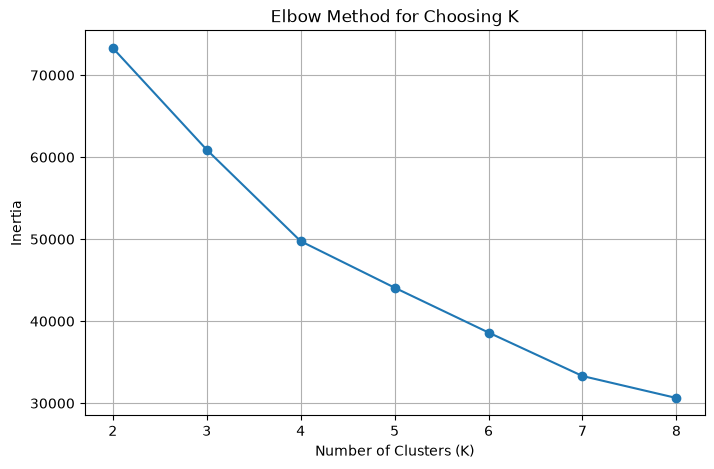

In [82]:
# ============================================
# DAY 4 - BLOCK 4
# FIND THE BEST K USING INERTIA
# ============================================

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []

k_values = range(2, 9)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_segment_scaled)

    inertia_values.append(kmeans.inertia_)


# ============================================
# DISPLAY INERTIA VALUES
# ============================================

print("================================")
print("K vs INERTIA")
print("================================")

for k, inertia in zip(k_values, inertia_values):
    print(f"K = {k}  →  Inertia = {inertia:.2f}")


# ============================================
# ELBOW PLOT
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [83]:
# ============================================
# DAY 4 - BLOCK 5
# FIT K-MEANS WITH K = 4
# ============================================

from sklearn.cluster import KMeans

# ============================================
# CREATE K-MEANS MODEL
# ============================================

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# ============================================
# FIT MODEL
# ============================================

kmeans.fit(X_segment_scaled)


# ============================================
# ASSIGN CLUSTER LABELS
# ============================================

cluster_labels = kmeans.labels_

print("================================")
print("K-MEANS CLUSTERING")
print("================================")

print("Number of clusters:", kmeans.n_clusters)

print("\nCluster labels:")
print(cluster_labels[:20])

print("\nCluster counts:")
print(
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
)


# ============================================
# ADD CLUSTER TO CUSTOMER DATA
# ============================================

segmented_customers = X_segment.copy()

segmented_customers["Cluster"] = cluster_labels

print("\nSegmented customer data:")
print(segmented_customers.head())

K-MEANS CLUSTERING
Number of clusters: 4

Cluster labels:
[2 0 1 0 0 0 1 0 1 0 0 0 1 1 0 0 1 2 1 0]

Cluster counts:
0    8348
1    9578
2    2067
3       7
Name: count, dtype: int64

Segmented customer data:
   transaction_count  total_transaction_value  average_transaction_value  \
0                3.0                 206238.0               68746.000000   
1                5.0                 326732.0               65346.400000   
2                6.0                 529603.0               88267.166667   
3                4.0                  62874.0               15718.500000   
4                5.0                 144995.0               28999.000000   

   account_count  total_balance  transactions_per_month  Cluster  
0            1.0       568990.0                1.666667        2  
1            1.0       451664.0                0.757576        0  
2            1.0       162156.0                0.769231        1  
3            1.0       375628.0                0.591133        0  

In [84]:
# ============================================
# DAY 4 - BLOCK 6
# PROFILE THE CUSTOMER CLUSTERS
# ============================================

cluster_profile = (
    segmented_customers
    .groupby("Cluster")[segmentation_features]
    .mean()
    .round(2)
)

print("================================")
print("CLUSTER PROFILE")
print("================================")

print(cluster_profile)


# ============================================
# CLUSTER SIZE
# ============================================

print("\n================================")
print("CLUSTER SIZE")
print("================================")

cluster_size = (
    segmented_customers["Cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_size)


# ============================================
# CLUSTER SIZE PERCENTAGE
# ============================================

print("\n================================")
print("CLUSTER SIZE (%)")
print("================================")

cluster_percentage = (
    segmented_customers["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(cluster_percentage)

CLUSTER PROFILE
         transaction_count  total_transaction_value  \
Cluster                                               
0                     2.31                172501.67   
1                     5.32                400907.46   
2                     2.50                184610.73   
3                     5.00               5324550.00   

         average_transaction_value  account_count  total_balance  \
Cluster                                                            
0                         74539.96           1.02      399367.21   
1                         75386.66           2.00      813687.33   
2                         73977.27           1.11      430345.21   
3                       1132418.95           1.86      793074.00   

         transactions_per_month  
Cluster                          
0                          0.70  
1                          0.92  
2                          2.04  
3                          0.84  

CLUSTER SIZE
Cluster
0    8348
1    957

In [85]:
# ============================================
# DAY 4 - BLOCK 7
# TEST K = 3
# ============================================

kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit K-Means
kmeans_3.fit(X_segment_scaled)


# ============================================
# ASSIGN CLUSTERS
# ============================================

cluster_labels_3 = kmeans_3.labels_


# ============================================
# CREATE K=3 DATASET
# ============================================

segmented_customers_3 = X_segment.copy()

segmented_customers_3["Cluster"] = cluster_labels_3


# ============================================
# PROFILE K=3
# ============================================

cluster_profile_3 = (
    segmented_customers_3
    .groupby("Cluster")[segmentation_features]
    .mean()
    .round(2)
)


print("================================")
print("K = 3 CLUSTER PROFILE")
print("================================")

print(cluster_profile_3)


# ============================================
# CLUSTER SIZE
# ============================================

print("\n================================")
print("K = 3 CLUSTER SIZE")
print("================================")

cluster_size_3 = (
    segmented_customers_3["Cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_size_3)


# ============================================
# CLUSTER SIZE %
# ============================================

print("\n================================")
print("K = 3 CLUSTER SIZE (%)")
print("================================")

cluster_percentage_3 = (
    segmented_customers_3["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(cluster_percentage_3)


# ============================================
# INERTIA
# ============================================

print("\n================================")
print("K = 3 INERTIA")
print("================================")

print(f"{kmeans_3.inertia_:.2f}")

K = 3 CLUSTER PROFILE
         transaction_count  total_transaction_value  \
Cluster                                               
0                     5.29                398337.61   
1                     2.32                172542.00   
2                     5.00               5324550.00   

         average_transaction_value  account_count  total_balance  \
Cluster                                                            
0                         75400.10           2.00      811705.52   
1                         74394.89           1.01      398692.85   
2                       1132418.95           1.86      793074.00   

         transactions_per_month  
Cluster                          
0                          0.95  
1                          0.94  
2                          0.84  

K = 3 CLUSTER SIZE
Cluster
0     9796
1    10197
2        7
Name: count, dtype: int64

K = 3 CLUSTER SIZE (%)
Cluster
0    48.98
1    50.98
2     0.03
Name: proportion, dtype: float64

K = 3

In [86]:
# ============================================
# DAY 4 - BLOCK 8
# FINALIZE K = 4 SEGMENTATION
# ============================================

# ============================================
# USE FINAL K-MEANS MODEL
# ============================================

final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

final_kmeans.fit(X_segment_scaled)


# ============================================
# GET FINAL CLUSTER LABELS
# ============================================

final_cluster_labels = final_kmeans.labels_


# ============================================
# CREATE FINAL SEGMENTATION DATASET
# ============================================

final_segments = X_segment.copy()

final_segments["Cluster"] = final_cluster_labels


# ============================================
# CLUSTER PROFILE
# ============================================

final_cluster_profile = (
    final_segments
    .groupby("Cluster")[segmentation_features]
    .mean()
    .round(2)
)


# ============================================
# CLUSTER COUNTS
# ============================================

final_cluster_counts = (
    final_segments["Cluster"]
    .value_counts()
    .sort_index()
)


# ============================================
# DISPLAY RESULTS
# ============================================

print("================================")
print("FINAL K-MEANS SEGMENTATION")
print("================================")

print("Number of clusters:")
print(final_kmeans.n_clusters)

print("\nCluster counts:")
print(final_cluster_counts)

print("\nCluster percentages:")
print(
    (
        final_cluster_counts
        / len(final_segments)
        * 100
    ).round(2)
)

print("\nFinal cluster profile:")
print(final_cluster_profile)

FINAL K-MEANS SEGMENTATION
Number of clusters:
4

Cluster counts:
Cluster
0    8348
1    9578
2    2067
3       7
Name: count, dtype: int64

Cluster percentages:
Cluster
0    41.74
1    47.89
2    10.34
3     0.03
Name: count, dtype: float64

Final cluster profile:
         transaction_count  total_transaction_value  \
Cluster                                               
0                     2.31                172501.67   
1                     5.32                400907.46   
2                     2.50                184610.73   
3                     5.00               5324550.00   

         average_transaction_value  account_count  total_balance  \
Cluster                                                            
0                         74539.96           1.02      399367.21   
1                         75386.66           2.00      813687.33   
2                         73977.27           1.11      430345.21   
3                       1132418.95           1.86      793074.0

In [87]:
# ============================================
# DAY 4 - BLOCK 9
# ASSIGN BUSINESS SEGMENT NAMES
# ============================================

segment_names = {
    0: "Low-Engagement Customers",
    1: "High-Value Core Customers",
    2: "Frequent-Activity Customers",
    3: "Extreme-Value Customers"
}


# ============================================
# ADD BUSINESS SEGMENT
# ============================================

final_segments["Segment"] = (
    final_segments["Cluster"]
    .map(segment_names)
)


# ============================================
# SEGMENT SUMMARY
# ============================================

segment_summary = (
    final_segments
    .groupby(["Cluster", "Segment"])[segmentation_features]
    .mean()
    .round(2)
)


print("================================")
print("FINAL BUSINESS SEGMENTS")
print("================================")

print(segment_summary)


# ============================================
# SEGMENT COUNTS
# ============================================

print("\n================================")
print("CUSTOMERS PER SEGMENT")
print("================================")

print(
    final_segments["Segment"]
    .value_counts()
)


# ============================================
# CHECK FOR MISSING SEGMENT NAMES
# ============================================

print("\n================================")
print("MISSING SEGMENT NAMES")
print("================================")

print(
    final_segments["Segment"]
    .isna()
    .sum()
)

FINAL BUSINESS SEGMENTS
                                     transaction_count  \
Cluster Segment                                          
0       Low-Engagement Customers                  2.31   
1       High-Value Core Customers                 5.32   
2       Frequent-Activity Customers               2.50   
3       Extreme-Value Customers                   5.00   

                                     total_transaction_value  \
Cluster Segment                                                
0       Low-Engagement Customers                   172501.67   
1       High-Value Core Customers                  400907.46   
2       Frequent-Activity Customers                184610.73   
3       Extreme-Value Customers                   5324550.00   

                                     average_transaction_value  account_count  \
Cluster Segment                                                                 
0       Low-Engagement Customers                      74539.96           1.02   

In [88]:
# ============================================
# DAY 4 - BLOCK 10
# CONNECT SEGMENTS WITH CHURN RISK
# ============================================

# ============================================
# CREATE RISK DATASET
# ============================================

risk_analysis = pd.DataFrame({
    "CustomerID": model_features["CustomerID"],
    "churn": y.values
})


# ============================================
# ADD FINAL CLUSTER
# ============================================

risk_analysis["Cluster"] = final_segments["Cluster"].values


# ============================================
# ADD BUSINESS SEGMENT
# ============================================

risk_analysis["Segment"] = (
    risk_analysis["Cluster"]
    .map(segment_names)
)


# ============================================
# CHURN RATE BY SEGMENT
# ============================================

segment_risk = (
    risk_analysis
    .groupby(["Cluster", "Segment"])
    .agg(
        customers=("churn", "size"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

segment_risk["churn_rate"] = (
    segment_risk["churn_rate"] * 100
).round(2)


# ============================================
# DISPLAY RESULTS
# ============================================

print("================================")
print("SEGMENT RISK ANALYSIS")
print("================================")

print(segment_risk)

SEGMENT RISK ANALYSIS
   Cluster                      Segment  customers  churned_customers  \
0        0     Low-Engagement Customers       8348               3662   
1        1    High-Value Core Customers       9578               1351   
2        2  Frequent-Activity Customers       2067                645   
3        3      Extreme-Value Customers          7                  1   

   churn_rate  
0       43.87  
1       14.11  
2       31.20  
3       14.29  


In [89]:
# ============================================
# DAY 4 - BLOCK 11
# VALUE + CHURN RISK ANALYSIS
# ============================================

# ============================================
# ADD BALANCE TO RISK DATASET
# ============================================

risk_analysis["total_balance"] = (
    final_segments["total_balance"].values
)


# ============================================
# ANALYZE EACH SEGMENT
# ============================================

value_risk_summary = (
    risk_analysis
    .groupby(["Cluster", "Segment"])
    .agg(
        customers=("CustomerID", "count"),
        average_balance=("total_balance", "mean"),
        total_balance=("total_balance", "sum"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)


# ============================================
# CONVERT CHURN TO PERCENTAGE
# ============================================

value_risk_summary["churn_rate"] = (
    value_risk_summary["churn_rate"] * 100
).round(2)

value_risk_summary["average_balance"] = (
    value_risk_summary["average_balance"]
    .round(2)
)

value_risk_summary["total_balance"] = (
    value_risk_summary["total_balance"]
    .round(2)
)


# ============================================
# DISPLAY
# ============================================

print("================================")
print("VALUE + RISK ANALYSIS")
print("================================")

print(value_risk_summary)

VALUE + RISK ANALYSIS
   Cluster                      Segment  customers  average_balance  \
0        0     Low-Engagement Customers       8348        399367.21   
1        1    High-Value Core Customers       9578        813687.33   
2        2  Frequent-Activity Customers       2067        430345.21   
3        3      Extreme-Value Customers          7        793074.00   

   total_balance  churned_customers  churn_rate  
0   3.333917e+09               3662       43.87  
1   7.793497e+09               1351       14.11  
2   8.895235e+08                645       31.20  
3   5.551518e+06                  1       14.29  


In [90]:
# ============================================
# DAY 4 - BLOCK 12
# RETENTION PRIORITY ANALYSIS
# ============================================

priority_analysis = value_risk_summary.copy()


# ============================================
# ESTIMATED BALANCE EXPOSED TO CHURN
# ============================================

priority_analysis["balance_exposed_to_churn"] = (
    priority_analysis["churned_customers"]
    * priority_analysis["average_balance"]
)


# ============================================
# ROUND VALUES
# ============================================

priority_analysis["balance_exposed_to_churn"] = (
    priority_analysis["balance_exposed_to_churn"]
    .round(2)
)


# ============================================
# SORT BY EXPOSURE
# ============================================

priority_analysis = priority_analysis.sort_values(
    "balance_exposed_to_churn",
    ascending=False
)


# ============================================
# DISPLAY
# ============================================

print("================================")
print("RETENTION PRIORITY ANALYSIS")
print("================================")

print(
    priority_analysis[
        [
            "Segment",
            "customers",
            "churned_customers",
            "churn_rate",
            "average_balance",
            "balance_exposed_to_churn"
        ]
    ]
)

RETENTION PRIORITY ANALYSIS
                       Segment  customers  churned_customers  churn_rate  \
0     Low-Engagement Customers       8348               3662       43.87   
1    High-Value Core Customers       9578               1351       14.11   
2  Frequent-Activity Customers       2067                645       31.20   
3      Extreme-Value Customers          7                  1       14.29   

   average_balance  balance_exposed_to_churn  
0        399367.21              1.462483e+09  
1        813687.33              1.099292e+09  
2        430345.21              2.775727e+08  
3        793074.00              7.930740e+05  


In [91]:
# ============================================
# DAY 4 - BLOCK 13
# FINAL BUSINESS RECOMMENDATIONS
# ============================================

business_recommendations = {
    "Low-Engagement Customers": {
        "priority": "HIGH",
        "focus": "Retention & Re-engagement",
        "reason": "Highest churn rate among major customer segments",
        "recommendation": "Use targeted re-engagement campaigns, personalized offers, and digital engagement strategies."
    },

    "High-Value Core Customers": {
        "priority": "HIGH",
        "focus": "Retention & Cross-Sell",
        "reason": "Largest balance exposure and strongest mainstream customer value",
        "recommendation": "Protect the relationship with premium services, cross-selling, and proactive retention."
    },

    "Frequent-Activity Customers": {
        "priority": "MEDIUM-HIGH",
        "focus": "Engagement & Retention",
        "reason": "High transaction frequency but relatively high churn rate",
        "recommendation": "Encourage continued usage through personalized products, digital engagement, and loyalty incentives."
    },

    "Extreme-Value Customers": {
        "priority": "SPECIALIZED",
        "focus": "Individual Review",
        "reason": "Very small segment with exceptionally large transaction values",
        "recommendation": "Handle as exceptional customers and investigate individually rather than applying broad campaigns."
    }
}


# ============================================
# DISPLAY RECOMMENDATIONS
# ============================================

print("================================")
print("BUSINESS RECOMMENDATIONS")
print("================================")

for segment, details in business_recommendations.items():

    print(f"\n{segment}")
    print("-" * len(segment))

    print("Priority:", details["priority"])
    print("Focus:", details["focus"])
    print("Reason:", details["reason"])
    print("Recommendation:", details["recommendation"])

BUSINESS RECOMMENDATIONS

Low-Engagement Customers
------------------------
Priority: HIGH
Focus: Retention & Re-engagement
Reason: Highest churn rate among major customer segments
Recommendation: Use targeted re-engagement campaigns, personalized offers, and digital engagement strategies.

High-Value Core Customers
-------------------------
Priority: HIGH
Focus: Retention & Cross-Sell
Reason: Largest balance exposure and strongest mainstream customer value
Recommendation: Protect the relationship with premium services, cross-selling, and proactive retention.

Frequent-Activity Customers
---------------------------
Priority: MEDIUM-HIGH
Focus: Engagement & Retention
Reason: High transaction frequency but relatively high churn rate
Recommendation: Encourage continued usage through personalized products, digital engagement, and loyalty incentives.

Extreme-Value Customers
-----------------------
Priority: SPECIALIZED
Focus: Individual Review
Reason: Very small segment with exceptionally 

In [92]:
# ============================================
# DAY 4 - BLOCK 14
# PRODUCT + CHANNEL OPPORTUNITIES
# ============================================

product_opportunities = {
    "Low-Engagement Customers": [
        "Digital banking activation",
        "Personalized transaction incentives",
        "Targeted retention offers",
        "Financial engagement campaigns"
    ],

    "High-Value Core Customers": [
        "Premium banking services",
        "Credit and lending products",
        "Investment products",
        "Additional account/cross-sell opportunities"
    ],

    "Frequent-Activity Customers": [
        "Digital payment products",
        "Transaction-based rewards",
        "Mobile banking engagement",
        "Loyalty programs"
    ],

    "Extreme-Value Customers": [
        "Relationship-manager review",
        "Premium banking services",
        "High-value transaction monitoring",
        "Individualized financial services"
    ]
}


print("================================")
print("PRODUCT & CHANNEL OPPORTUNITIES")
print("================================")

for segment, opportunities in product_opportunities.items():

    print(f"\n{segment}")

    for opportunity in opportunities:
        print("  -", opportunity)

PRODUCT & CHANNEL OPPORTUNITIES

Low-Engagement Customers
  - Digital banking activation
  - Personalized transaction incentives
  - Targeted retention offers
  - Financial engagement campaigns

High-Value Core Customers
  - Premium banking services
  - Credit and lending products
  - Investment products
  - Additional account/cross-sell opportunities

Frequent-Activity Customers
  - Digital payment products
  - Transaction-based rewards
  - Mobile banking engagement
  - Loyalty programs

Extreme-Value Customers
  - Relationship-manager review
  - Premium banking services
  - High-value transaction monitoring
  - Individualized financial services


In [93]:
# ============================================
# DAY 4 - BLOCK 15
# FINAL SEGMENTATION SUMMARY
# ============================================

final_segmentation_summary = (
    value_risk_summary[
        [
            "Cluster",
            "Segment",
            "customers",
            "average_balance",
            "total_balance",
            "churned_customers",
            "churn_rate"
        ]
    ]
    .copy()
)


# ============================================
# ADD CUSTOMER PERCENTAGE
# ============================================

final_segmentation_summary["customer_percentage"] = (
    final_segmentation_summary["customers"]
    / final_segmentation_summary["customers"].sum()
    * 100
).round(2)


# ============================================
# SORT BY CUSTOMER COUNT
# ============================================

final_segmentation_summary = (
    final_segmentation_summary
    .sort_values("customers", ascending=False)
    .reset_index(drop=True)
)


# ============================================
# DISPLAY
# ============================================

print("================================")
print("FINAL CUSTOMER SEGMENTATION")
print("================================")

print(final_segmentation_summary)

FINAL CUSTOMER SEGMENTATION
   Cluster                      Segment  customers  average_balance  \
0        1    High-Value Core Customers       9578        813687.33   
1        0     Low-Engagement Customers       8348        399367.21   
2        2  Frequent-Activity Customers       2067        430345.21   
3        3      Extreme-Value Customers          7        793074.00   

   total_balance  churned_customers  churn_rate  customer_percentage  
0   7.793497e+09               1351       14.11                47.89  
1   3.333917e+09               3662       43.87                41.74  
2   8.895235e+08                645       31.20                10.34  
3   5.551518e+06                  1       14.29                 0.03  


In [96]:
# ============================================
# DAY 4 - BLOCK 16
# SAVE DAY 4 OUTPUTS
# ============================================

import os

output_dir = "../data/outputs"

os.makedirs(output_dir, exist_ok=True)


# ============================================
# SAVE SEGMENTED CUSTOMERS
# ============================================

final_segments.to_csv(
    f"{output_dir}/customer_segments.csv",
    index=False
)


# ============================================
# SAVE SEGMENT RISK
# ============================================

segment_risk.to_csv(
    f"{output_dir}/segment_risk_analysis.csv",
    index=False
)


# ============================================
# SAVE VALUE + RISK
# ============================================

value_risk_summary.to_csv(
    f"{output_dir}/segment_value_risk.csv",
    index=False
)


# ============================================
# SAVE RETENTION PRIORITY
# ============================================

priority_analysis.to_csv(
    f"{output_dir}/retention_priority_analysis.csv",
    index=False
)


# ============================================
# SAVE FINAL SUMMARY
# ============================================

final_segmentation_summary.to_csv(
    f"{output_dir}/final_segmentation_summary.csv",
    index=False
)


print("================================")
print("DAY 4 OUTPUTS SAVED")
print("================================")

print("Output directory:", output_dir)

print("\nFiles created:")

print("1. customer_segments.csv")
print("2. segment_risk_analysis.csv")
print("3. segment_value_risk.csv")
print("4. retention_priority_analysis.csv")
print("5. final_segmentation_summary.csv")

DAY 4 OUTPUTS SAVED
Output directory: ../data/outputs

Files created:
1. customer_segments.csv
2. segment_risk_analysis.csv
3. segment_value_risk.csv
4. retention_priority_analysis.csv
5. final_segmentation_summary.csv


In [102]:
customers = pd.read_csv("../data/outputs/customer_segments.csv")
customers.head()

,transaction_count,total_transaction_value,average_transaction_value,account_count,total_balance,transactions_per_month,Cluster,Segment
0,3.0,206238.0,68746.000000,1.0,568990.0,1.666667,2,Frequent-Activity Customers
1,5.0,326732.0,65346.400000,1.0,451664.0,0.757576,0,Low-Engagement Customers
2,6.0,529603.0,88267.166667,1.0,162156.0,0.769231,1,High-Value Core Customers
3,4.0,62874.0,15718.500000,1.0,375628.0,0.591133,0,Low-Engagement Customers
4,5.0,144995.0,28999.000000,1.0,29324.0,0.714286,0,Low-Engagement Customers


In [103]:
# ============================================
# DAY 5 - PREPARE FINAL POWER BI SEGMENT DATA
# ============================================

# Add CustomerID to final segmentation data
final_segments_powerbi = final_segments.copy()

final_segments_powerbi.insert(
    0,
    "CustomerID",
    model_features["CustomerID"].values
)


# ============================================
# CHECK
# ============================================

print("================================")
print("POWER BI CUSTOMER SEGMENTS")
print("================================")

print("Shape:")
print(final_segments_powerbi.shape)

print("\nColumns:")
print(final_segments_powerbi.columns.tolist())

print("\nUnique customers:")
print(final_segments_powerbi["CustomerID"].nunique())

print("\nDuplicate CustomerIDs:")
print(final_segments_powerbi["CustomerID"].duplicated().sum())

print("\nPreview:")
print(final_segments_powerbi.head())

POWER BI CUSTOMER SEGMENTS
Shape:
(20000, 9)

Columns:
['CustomerID', 'transaction_count', 'total_transaction_value', 'average_transaction_value', 'account_count', 'total_balance', 'transactions_per_month', 'Cluster', 'Segment']

Unique customers:
20000

Duplicate CustomerIDs:
0

Preview:
   CustomerID  transaction_count  total_transaction_value  \
0           1                3.0                 206238.0   
1           2                5.0                 326732.0   
2           3                6.0                 529603.0   
3           4                4.0                  62874.0   
4           5                5.0                 144995.0   

   average_transaction_value  account_count  total_balance  \
0               68746.000000            1.0       568990.0   
1               65346.400000            1.0       451664.0   
2               88267.166667            1.0       162156.0   
3               15718.500000            1.0       375628.0   
4               28999.000000     

In [104]:
# ============================================
# SAVE CORRECTED POWER BI FILE
# ============================================

final_segments_powerbi.to_csv(
    "../data/outputs/customer_segments.csv",
    index=False
)

print("customer_segments.csv updated successfully.")

customer_segments.csv updated successfully.


In [105]:
# ============================================
# DAY 5 - BLOCK 1
# CREATE POWER BI MASTER DATASET
# ============================================

# Start with final customer segmentation
powerbi_master = final_segments_powerbi.copy()


# ============================================
# ADD CHURN TARGET
# ============================================

powerbi_master["churn"] = y.values


# ============================================
# ADD CHURN LABEL
# ============================================

powerbi_master["Churn_Status"] = (
    powerbi_master["churn"]
    .map({
        0: "Active",
        1: "Churned"
    })
)


# ============================================
# CHECK DATASET
# ============================================

print("================================")
print("POWER BI MASTER DATASET")
print("================================")

print("Shape:")
print(powerbi_master.shape)

print("\nColumns:")
print(powerbi_master.columns.tolist())

print("\nMissing values:")
print(powerbi_master.isna().sum())

print("\nDuplicate CustomerIDs:")
print(powerbi_master["CustomerID"].duplicated().sum())

print("\nPreview:")
print(powerbi_master.head())

POWER BI MASTER DATASET
Shape:
(20000, 11)

Columns:
['CustomerID', 'transaction_count', 'total_transaction_value', 'average_transaction_value', 'account_count', 'total_balance', 'transactions_per_month', 'Cluster', 'Segment', 'churn', 'Churn_Status']

Missing values:
CustomerID                   0
transaction_count            0
total_transaction_value      0
average_transaction_value    0
account_count                0
total_balance                0
transactions_per_month       0
Cluster                      0
Segment                      0
churn                        0
Churn_Status                 0
dtype: int64

Duplicate CustomerIDs:
0

Preview:
   CustomerID  transaction_count  total_transaction_value  \
0           1                3.0                 206238.0   
1           2                5.0                 326732.0   
2           3                6.0                 529603.0   
3           4                4.0                  62874.0   
4           5                5.0    

In [106]:
# ============================================
# SAVE POWER BI MASTER DATASET
# ============================================

powerbi_master.to_csv(
    "../data/outputs/powerbi_master.csv",
    index=False
)

print("powerbi_master.csv saved successfully.")

powerbi_master.csv saved successfully.
